# Log File Parsing for Cybersecurity Intrusion Detection
## Machine Learning Review – CICIDS 2017

**Dataset:** Canadian Institute for Cybersecurity – IDS 2017  
**Source:** https://www.unb.ca/cic/datasets/ids-2017.html

| | |
|---|---|
| **Part A** | 5 Classification Algorithms (Binary IDS – Benign vs Attack) |
| **Part B** | 10 Regression Algorithms (Predicting Flow Duration) |

### Pipeline
1. Data Collection & Understanding
2. Data Cleaning
3. Feature Engineering
4. Handling Class Imbalance
5. **Part A – Model Building (Classification × 5)**
6. **Part B – Model Building (Regression × 10)**
7. Evaluation
8. Optional Extension
---

## PHASE 1 – Data Collection & Understanding

In [1]:
# ── 1.0  Imports ─────────────────────────────────────────────────────
import os, warnings, sys, time, re
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: "%.4f" % x)

RANDOM_STATE = 42
print("Libraries loaded successfully.")


Libraries loaded successfully.


In [2]:
# ── 1.1  Load all 8 CSV files ────────────────────────────────────────
# CICIDS 2017: 5 days of network capture, features extracted by CICFlowMeter.
# Each row = one bidirectional network flow.
DATA_DIR = r"c:\Users\manda\Downloads\MLREVIEW1"

csv_files = [
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
]

dfs = []
for fname in csv_files:
    tmp = pd.read_csv(os.path.join(DATA_DIR, fname),
                      low_memory=False, encoding="utf-8", encoding_errors="replace")
    dfs.append(tmp)
    print(f"  {fname}  -> shape {tmp.shape}")

df = pd.concat(dfs, ignore_index=True)
df.columns = df.columns.str.strip()
print(f"\nCombined Dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")


  Monday-WorkingHours.pcap_ISCX.csv  -> shape (529918, 79)


  Tuesday-WorkingHours.pcap_ISCX.csv  -> shape (445909, 79)


  Wednesday-workingHours.pcap_ISCX.csv  -> shape (692703, 79)


  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv  -> shape (170366, 79)


  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv  -> shape (288602, 79)


  Friday-WorkingHours-Morning.pcap_ISCX.csv  -> shape (191033, 79)


  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv  -> shape (225745, 79)


  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv  -> shape (286467, 79)



Combined Dataset: 2,830,743 rows x 79 columns


In [3]:
# ── 1.2  Dataset Overview ────────────────────────────────────────────
print("Columns:", df.columns.tolist())
print("\nDtypes:\n", df.dtypes.value_counts())
display(df.head(3))


Columns: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE F

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,49188,4,2,0,12,0,6,6,6.0000,0.0000,...,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
1,49188,1,2,0,12,0,6,6,6.0000,0.0000,...,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN
2,49188,1,2,0,12,0,6,6,6.0000,0.0000,...,20,0.0000,0.0000,0,0,0.0000,0.0000,0,0,BENIGN


=== CLASS DISTRIBUTION ===
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11

Total classes: 15


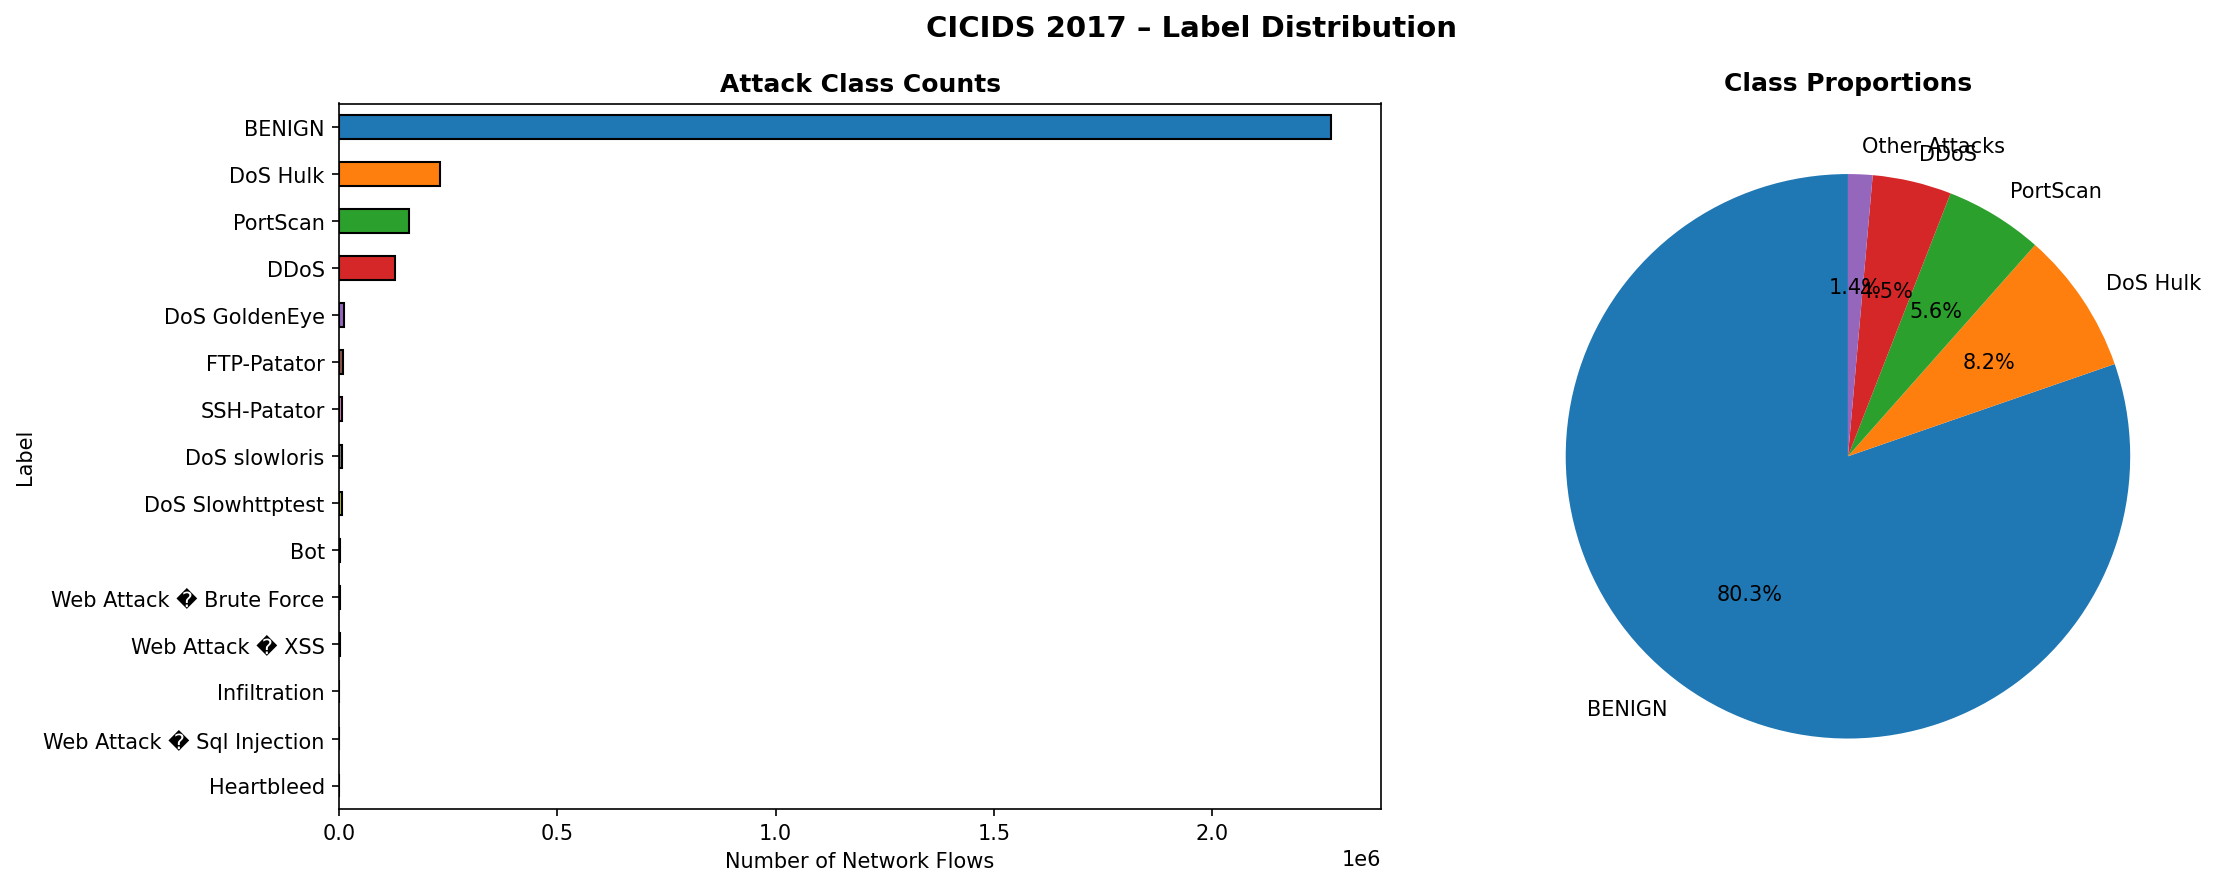

In [4]:
# ── 1.3  Label Distribution ──────────────────────────────────────────
label_counts = df["Label"].value_counts()
print("=== CLASS DISTRIBUTION ===")
print(label_counts.to_string())
print(f"\nTotal classes: {len(label_counts)}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
label_counts.plot(kind="barh", ax=axes[0],
                  color=sns.color_palette("tab10", len(label_counts)), edgecolor="black")
axes[0].set_title("Attack Class Counts", fontweight="bold")
axes[0].invert_yaxis()
axes[0].set_xlabel("Number of Network Flows")

threshold = label_counts.sum() * 0.005
big = label_counts[label_counts >= threshold].copy()
big["Other Attacks"] = label_counts[label_counts < threshold].sum()
axes[1].pie(big, labels=big.index, autopct="%1.1f%%",
            colors=sns.color_palette("tab10", len(big)), startangle=90)
axes[1].set_title("Class Proportions", fontweight="bold")
plt.suptitle("CICIDS 2017 – Label Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
# ── 1.4  Descriptive Statistics ──────────────────────────────────────
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
Destination Port,2830743.0000,8071.4825,18283.6322,0.0000,53.0000,80.0000,443.0000,65535.0000
Flow Duration,2830743.0000,14785663.9295,33653744.0859,-13.0000,155.0000,31316.0000,3204828.5000,119999998.0000
Total Fwd Packets,2830743.0000,9.3612,749.6728,1.0000,2.0000,2.0000,5.0000,219759.0000
Total Backward Packets,2830743.0000,10.3938,997.3883,0.0000,1.0000,2.0000,4.0000,291922.0000
Total Length of Fwd Packets,2830743.0000,549.3024,9993.5892,0.0000,12.0000,62.0000,187.0000,12900000.0000
...,...,...,...,...,...,...,...,...
Active Min,2830743.0000,58295.8177,577092.2819,0.0000,0.0000,0.0000,0.0000,110000000.0000
Idle Mean,2830743.0000,8316036.6272,23630078.5780,0.0000,0.0000,0.0000,0.0000,120000000.0000
Idle Std,2830743.0000,503843.9498,4602984.4807,0.0000,0.0000,0.0000,0.0000,76900000.0000
Idle Max,2830743.0000,8695751.9846,24366888.3290,0.0000,0.0000,0.0000,0.0000,120000000.0000


## PHASE 2 – Data Cleaning

In [6]:
# ── 2.1  Missing Value Analysis ──────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
miss_df = pd.DataFrame({"Count": missing, "Pct (%)": missing_pct})
miss_df = miss_df[miss_df["Count"] > 0].sort_values("Pct (%)", ascending=False)

if len(miss_df) == 0:
    print("No missing values found.")
else:
    display(miss_df)
    drop_cols = miss_df[miss_df["Pct (%)"] > 50].index.tolist()
    if drop_cols:
        df.drop(columns=drop_cols, inplace=True)
        print(f"Dropped (>50% NaN): {drop_cols}")
    num_cols = df.select_dtypes(include=[np.number]).columns
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    print("Remaining NaN filled with median.")

print(f"Shape after NaN handling: {df.shape}")


,Count,Pct (%)
Flow Bytes/s,1358,0.0480


Remaining NaN filled with median.
Shape after NaN handling: (2830743, 79)


In [7]:
# ── 2.2  Infinite Values (CICFlowMeter artefact) ─────────────────────
# Flow Bytes/s = total_bytes / duration. When duration=0 -> Inf.
num_cols = df.select_dtypes(include=[np.number]).columns
inf_cols = {c: int(np.isinf(df[c]).sum()) for c in num_cols if np.isinf(df[c]).sum() > 0}

print("=== INFINITE VALUE CHECK ===")
if not inf_cols:
    print("No Inf values found.")
else:
    for c, n in inf_cols.items():
        print(f"  {c}: {n} Inf values")
    for c in inf_cols:
        max_fin = float(df[c][np.isfinite(df[c])].max())
        df[c] = df[c].apply(lambda v: max_fin if not np.isfinite(v) else v)
    print("Inf replaced with column finite maximum.")

# Clip to float32-safe range (prevents sklearn ValueError)
num_cols = df.select_dtypes(include=[np.number]).columns
for c in num_cols:
    df[c] = df[c].clip(lower=-1e15, upper=1e15)

remaining = sum(int(np.isinf(df[c]).sum()) for c in num_cols)
print(f"Remaining Inf: {remaining}  |  Shape: {df.shape}")


=== INFINITE VALUE CHECK ===
  Flow Bytes/s: 1509 Inf values
  Flow Packets/s: 2867 Inf values


Inf replaced with column finite maximum.


Remaining Inf: 0  |  Shape: (2830743, 79)


In [8]:
# ── 2.3  Duplicate Rows ──────────────────────────────────────────────
init = len(df)
df.drop_duplicates(inplace=True)
print(f"Removed {init - len(df):,} duplicates. Shape: {df.shape}")


Removed 308,381 duplicates. Shape: (2522362, 79)


In [9]:
# ── 2.4  Zero-Variance (Constant) Columns ────────────────────────────
num_cols = df.select_dtypes(include=[np.number]).columns
zv = num_cols[df[num_cols].std() == 0].tolist()
if zv:
    df.drop(columns=zv, inplace=True)
    print(f"Dropped constant columns: {zv}")
else:
    print("No zero-variance columns.")
print(f"Shape: {df.shape}")


Dropped constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Shape: (2522362, 71)


In [10]:
# ── 2.5  Label Encoding ──────────────────────────────────────────────
df["Label"] = df["Label"].str.strip()
df["Label"] = df["Label"].apply(lambda x: re.sub(r"[^\x00-\x7F]+", "", str(x)).strip())

label_map = {
    "Web Attack  Brute Force":   "Web Attack-Brute Force",
    "Web Attack  XSS":           "Web Attack-XSS",
    "Web Attack  Sql Injection": "Web Attack-SQL Injection",
    "Web Attack Brute Force":    "Web Attack-Brute Force",
    "Web Attack XSS":            "Web Attack-XSS",
    "Web Attack Sql Injection":  "Web Attack-SQL Injection",
}
df["Label"] = df["Label"].replace(label_map)

# Binary label: 0=BENIGN, 1=ATTACK
df["label_binary"] = (df["Label"] != "BENIGN").astype(int)

# Multiclass label
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["label_multi"] = le.fit_transform(df["Label"])
class_names = le.classes_

print("Binary distribution:")
print(df["label_binary"].value_counts().to_string())
print("\nMulticlass classes:")
for i, n in enumerate(class_names):
    c = int((df["label_multi"] == i).sum())
    print(f"  {i:2d}: {n:42s} -> {c:,}")


Binary distribution:
label_binary
0    2096484
1     425878

Multiclass classes:
   0: BENIGN                                     -> 2,096,484
   1: Bot                                        -> 1,953
   2: DDoS                                       -> 128,016
   3: DoS GoldenEye                              -> 10,286
   4: DoS Hulk                                   -> 172,849
   5: DoS Slowhttptest                           -> 5,228
   6: DoS slowloris                              -> 5,385
   7: FTP-Patator                                -> 5,933
   8: Heartbleed                                 -> 11
   9: Infiltration                               -> 36
  10: PortScan                                   -> 90,819
  11: SSH-Patator                                -> 3,219
  12: Web Attack-Brute Force                     -> 1,470
  13: Web Attack-SQL Injection                   -> 21
  14: Web Attack-XSS                             -> 652


## PHASE 3 – Feature Engineering

High-correlation pairs (|r|>0.95): 67
  Bwd Packet Length Max               <->  Avg Bwd Segment Size                r=0.959
  Bwd Packet Length Mean              <->  Avg Bwd Segment Size                r=1.000
  Bwd Packet Length Mean              <->  Bwd Packet Length Max               r=0.959
  Bwd Packet Length Std               <->  Bwd Packet Length Max               r=0.983
  Fwd Header Length                   <->  Bwd Header Length                   r=1.000
  Fwd Header Length.1                 <->  Bwd Header Length                   r=1.000
  Fwd Header Length.1                 <->  Fwd Header Length                   r=1.000
  Fwd IAT Max                         <->  Flow IAT Max                        r=0.998



Removed 24 redundant cols. Remaining: 46


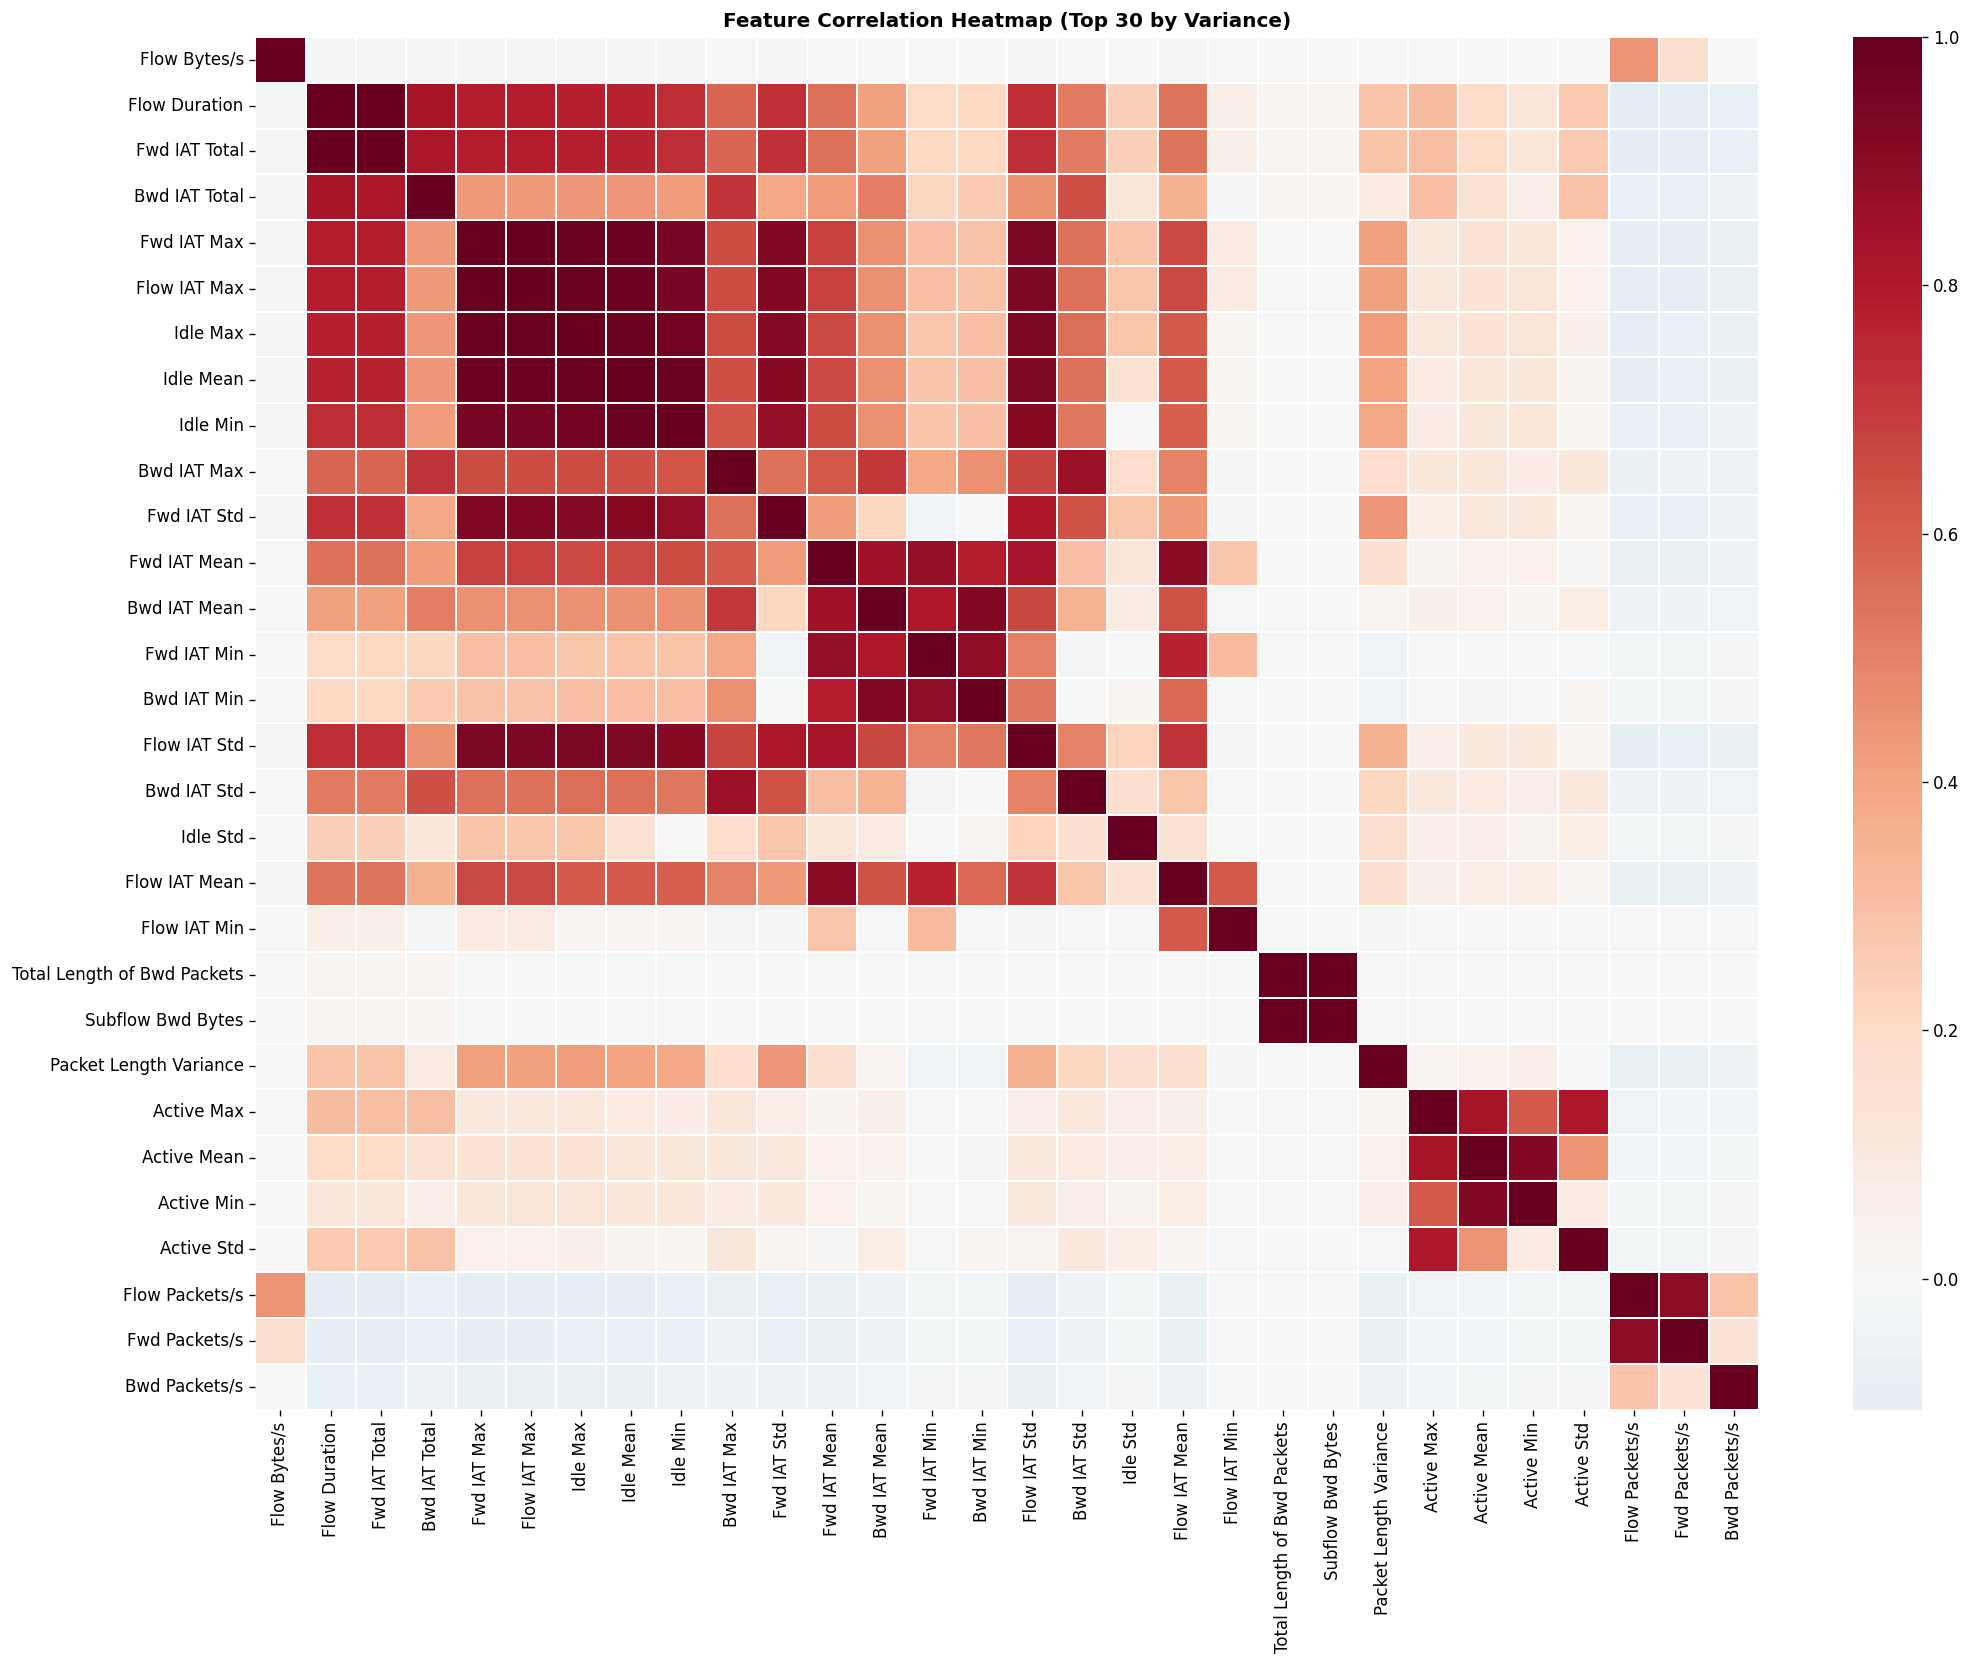

In [11]:
# ── 3.1  Correlation Heatmap & Pruning ───────────────────────────────
# Remove highly correlated features (|r| > 0.95) to reduce redundancy.
num_feats = df.select_dtypes(include=[np.number]).columns.difference(
    ["label_binary", "label_multi"])

sample_df = df[num_feats].sample(min(50_000, len(df)), random_state=RANDOM_STATE)
corr_mat = sample_df.corr()

high_pairs = []
for i in range(len(corr_mat.columns)):
    for j in range(i):
        r = corr_mat.iloc[i, j]
        if abs(r) > 0.95:
            high_pairs.append((corr_mat.columns[i], corr_mat.columns[j], r))

print(f"High-correlation pairs (|r|>0.95): {len(high_pairs)}")
for a, b, r in high_pairs[:8]:
    print(f"  {a[:34]:34s}  <->  {b[:34]:34s}  r={r:.3f}")

# Heatmap
top30 = sample_df.var().nlargest(30).index
fig, ax = plt.subplots(figsize=(18, 14))
sns.heatmap(sample_df[top30].corr(), cmap="RdBu_r", center=0,
            linewidths=0.1, ax=ax, annot=False)
ax.set_title("Feature Correlation Heatmap (Top 30 by Variance)", fontweight="bold")
plt.tight_layout()
plt.show()

cols_remove = {b for a, b, r in high_pairs}
cols_keep = [c for c in num_feats if c not in cols_remove]
print(f"\nRemoved {len(cols_remove)} redundant cols. Remaining: {len(cols_keep)}")

Selected top 30 features.

Top-20 feature importances:
Bwd Packet Length Mean        0.1362
Packet Length Variance        0.1122
Bwd Packet Length Std         0.1056
Packet Length Mean            0.0678
Packet Length Std             0.0558
Destination Port              0.0362
Total Length of Fwd Packets   0.0356
Fwd IAT Total                 0.0323
Flow Packets/s                0.0315
Flow IAT Std                  0.0284
act_data_pkt_fwd              0.0280
Idle Min                      0.0273
PSH Flag Count                0.0256
Fwd Packet Length Mean        0.0250
Bwd Packets/s                 0.0215
Fwd IAT Mean                  0.0197
min_seg_size_forward          0.0182
Fwd IAT Std                   0.0181
Init_Win_bytes_backward       0.0156
Init_Win_bytes_forward        0.0156


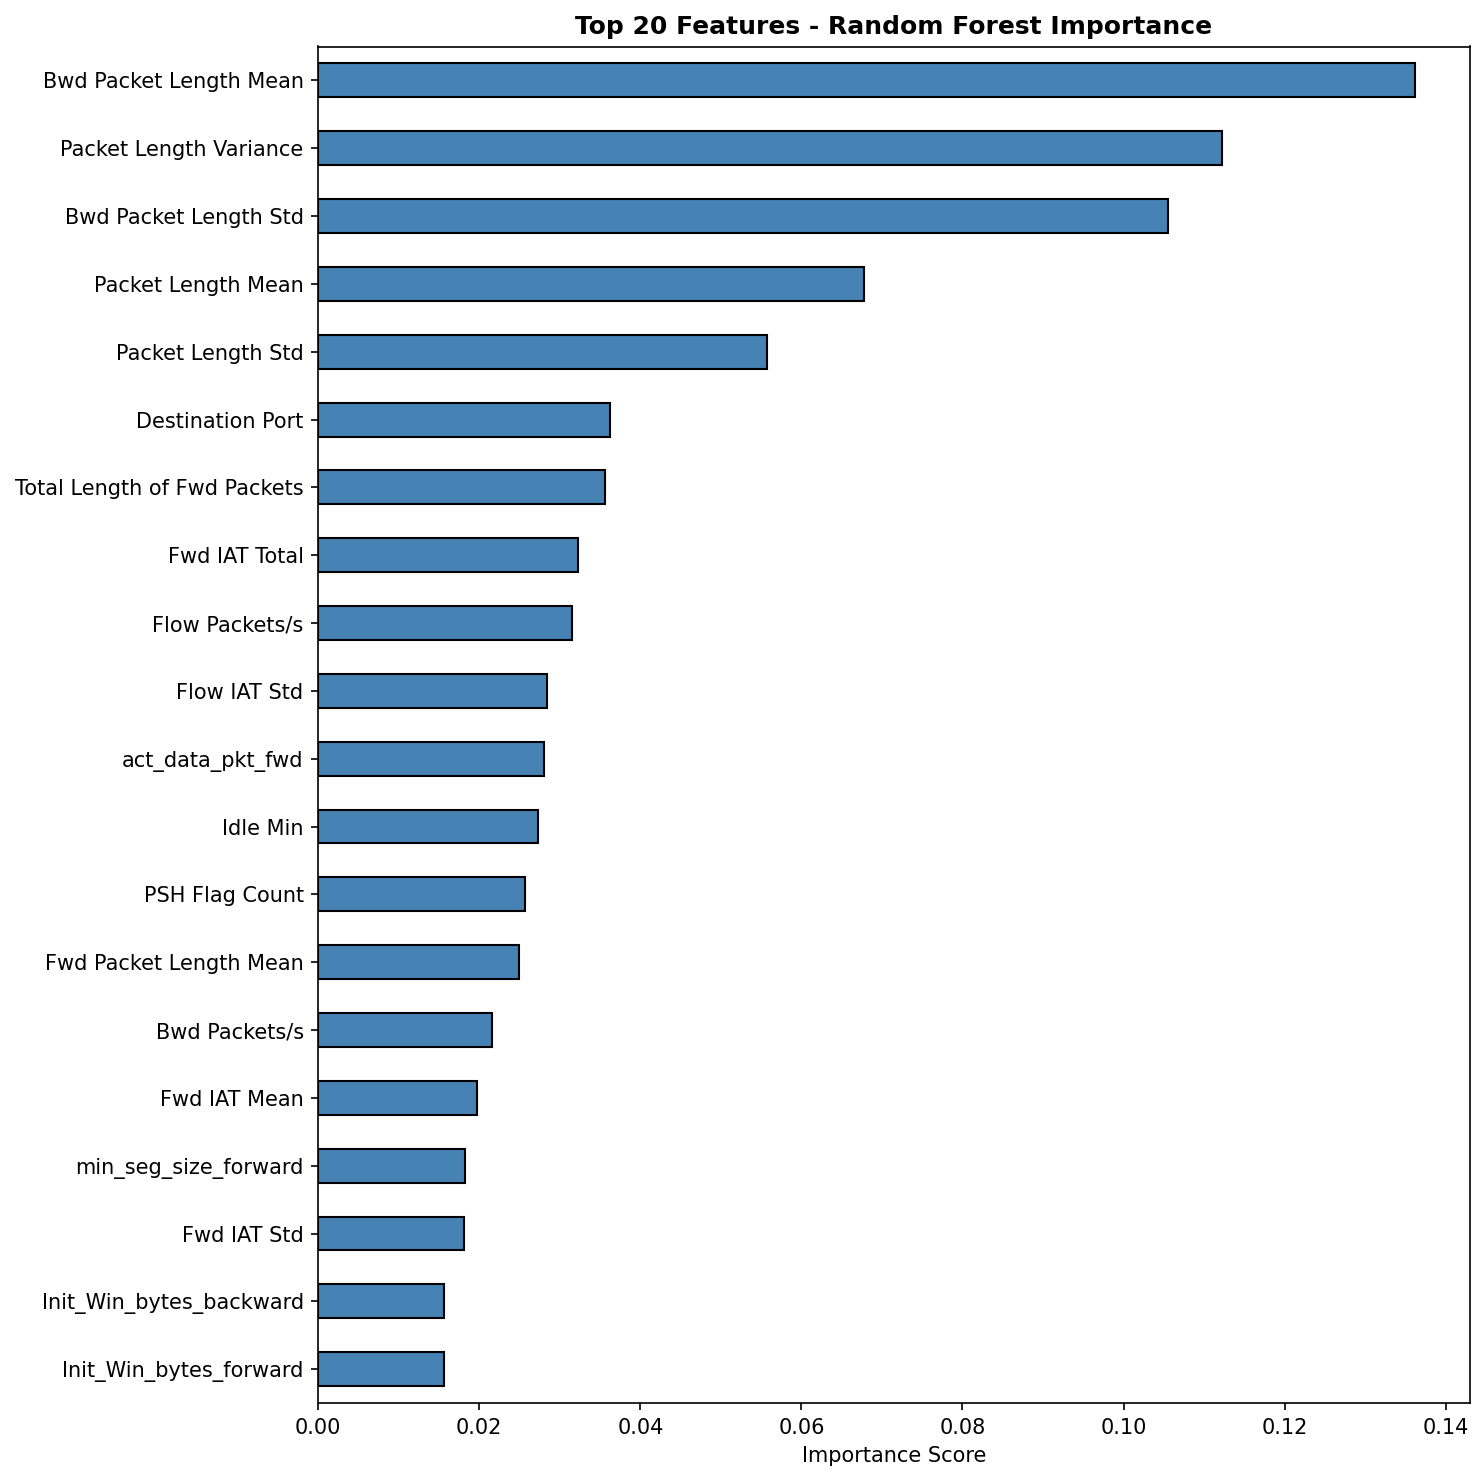

In [12]:
# ── 3.2  Random Forest Feature Importance ────────────────────────────
from sklearn.ensemble import RandomForestClassifier

SAMPLE_N = 100_000
si = df.sample(min(SAMPLE_N, len(df)), random_state=RANDOM_STATE).index
X_samp = df.loc[si, cols_keep]
y_samp = df.loc[si, "label_binary"]

rf_imp = RandomForestClassifier(n_estimators=50, max_depth=10,
                                random_state=RANDOM_STATE, n_jobs=-1)
rf_imp.fit(X_samp, y_samp)

importances = pd.Series(rf_imp.feature_importances_,
                        index=cols_keep).sort_values(ascending=False)
TOP_N = 30
selected_features = importances.head(TOP_N).index.tolist()
print(f"Selected top {TOP_N} features.")
print("\nTop-20 feature importances:")
print(importances.head(20).to_string())

fig, ax = plt.subplots(figsize=(10, 10))
importances.head(20).plot(kind="barh", ax=ax, color="steelblue", edgecolor="black")
ax.invert_yaxis()
ax.set_title("Top 20 Features - Random Forest Importance", fontweight="bold")
ax.set_xlabel("Importance Score")
plt.tight_layout()
plt.show()

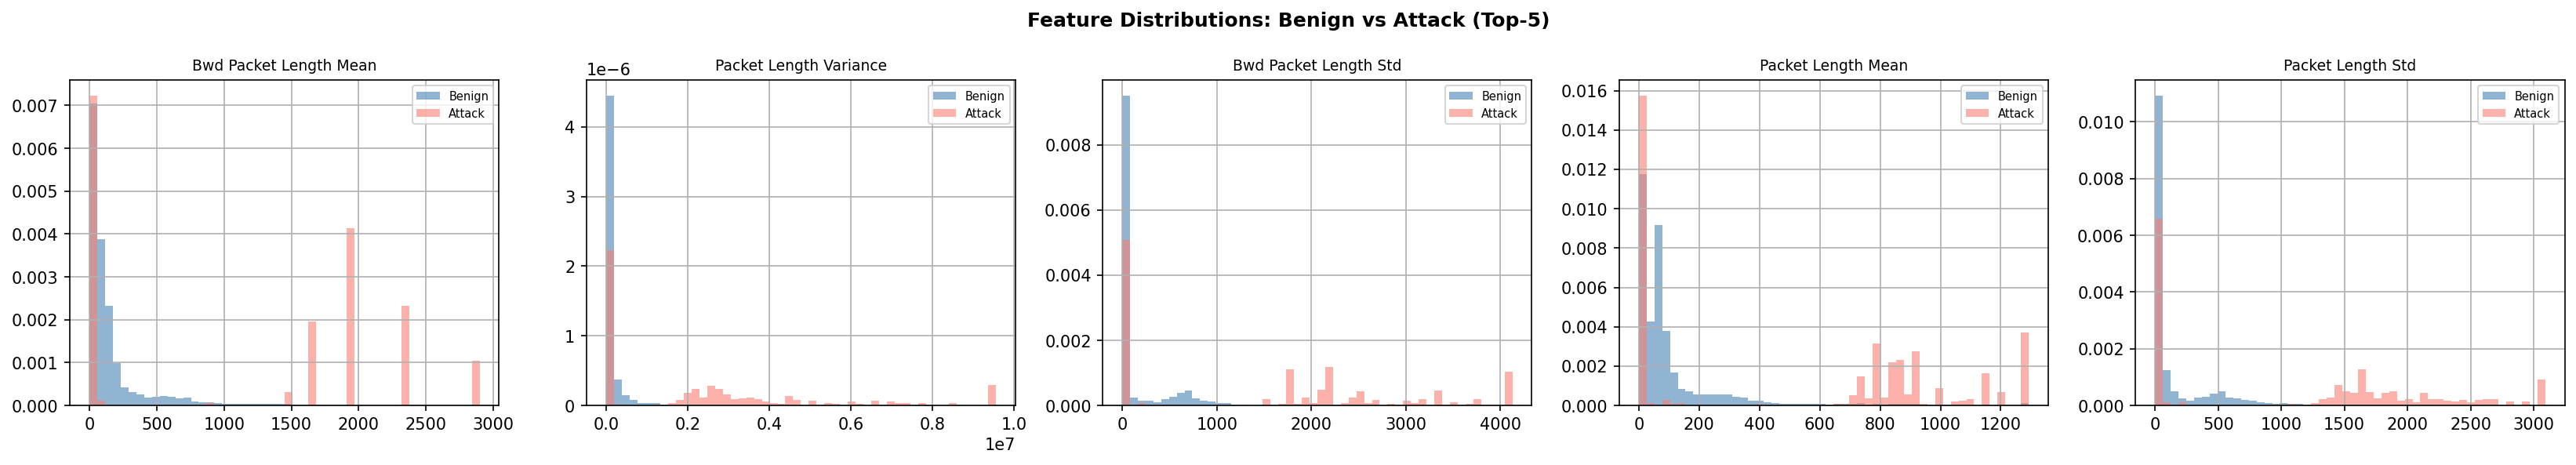

In [13]:
# ── 3.3  Feature Distributions (Benign vs Attack) ────────────────────
top5 = importances.head(5).index.tolist()
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, feat in zip(axes, top5):
    upper = df[feat].quantile(0.99)
    df[df["label_binary"]==0][feat].clip(upper=upper).hist(
        ax=ax, bins=50, alpha=0.6, color="steelblue", label="Benign", density=True)
    df[df["label_binary"]==1][feat].clip(upper=upper).hist(
        ax=ax, bins=50, alpha=0.6, color="salmon",   label="Attack", density=True)
    ax.set_title(feat[:24], fontsize=9)
    ax.legend(fontsize=7)
plt.suptitle("Feature Distributions: Benign vs Attack (Top-5)", fontweight="bold")
plt.tight_layout()
plt.show()

In [14]:
# ── 3.4  StandardScaler ───────────────────────────────────────────────
# Formula: z = (x - mean) / std
# Essential for LR, KNN; harmless for tree-based models.
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X       = df[selected_features].copy()
y_bin   = df["label_binary"].copy()
y_multi = df["label_multi"].copy()

scaler   = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X),
                        columns=selected_features, index=X.index)
print(f"Scaled feature matrix: {X_scaled.shape}")


Scaled feature matrix: (2522362, 30)


## PHASE 4 – Handling Class Imbalance

BENIGN : 2,096,484  (83.1%)
ATTACK : 425,878  (16.9%)
Imbalance Ratio: 4.9:1


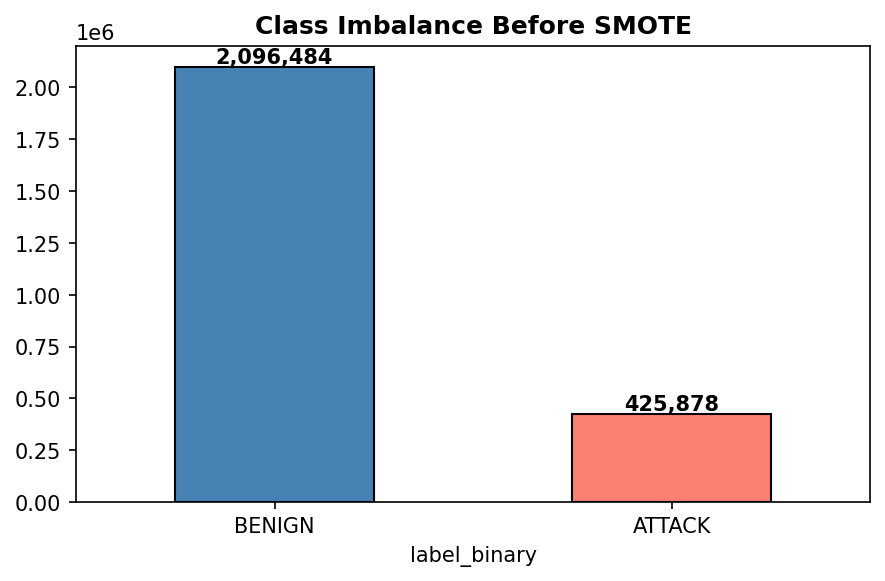

In [15]:
# ── 4.1  Quantify Imbalance ──────────────────────────────────────────
vc = y_bin.value_counts()
print(f"BENIGN : {vc[0]:,}  ({100*vc[0]/len(y_bin):.1f}%)")
print(f"ATTACK : {vc[1]:,}  ({100*vc[1]/len(y_bin):.1f}%)")
print(f"Imbalance Ratio: {vc[0]/vc[1]:.1f}:1")

fig, ax = plt.subplots(figsize=(6, 4))
vc.plot(kind="bar", ax=ax, color=["steelblue","salmon"], edgecolor="black")
ax.set_xticklabels(["BENIGN","ATTACK"], rotation=0)
ax.set_title("Class Imbalance Before SMOTE", fontweight="bold")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x()+p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()

In [16]:
# ── 4.2  Train/Test Split (BEFORE SMOTE – prevents data leakage) ─────
X_train, X_test, y_train_bin, y_test_bin, y_train_multi, y_test_multi = (
    train_test_split(X_scaled, y_bin, y_multi,
                     test_size=0.2, random_state=RANDOM_STATE, stratify=y_bin)
)
print(f"Train: {X_train.shape[0]:,}  |  Test: {X_test.shape[0]:,}")
print(f"Train BENIGN: {(y_train_bin==0).sum():,}  | ATTACK: {(y_train_bin==1).sum():,}")
print(f"Test  BENIGN: {(y_test_bin==0).sum():,}   | ATTACK: {(y_test_bin==1).sum():,}")


Train: 2,017,889  |  Test: 504,473
Train BENIGN: 1,677,187  | ATTACK: 340,702
Test  BENIGN: 419,297   | ATTACK: 85,176


After SMOTE -- BENIGN: 1,677,187  |  ATTACK: 1,677,187
New ratio: 1.00:1   Total: 3,354,374


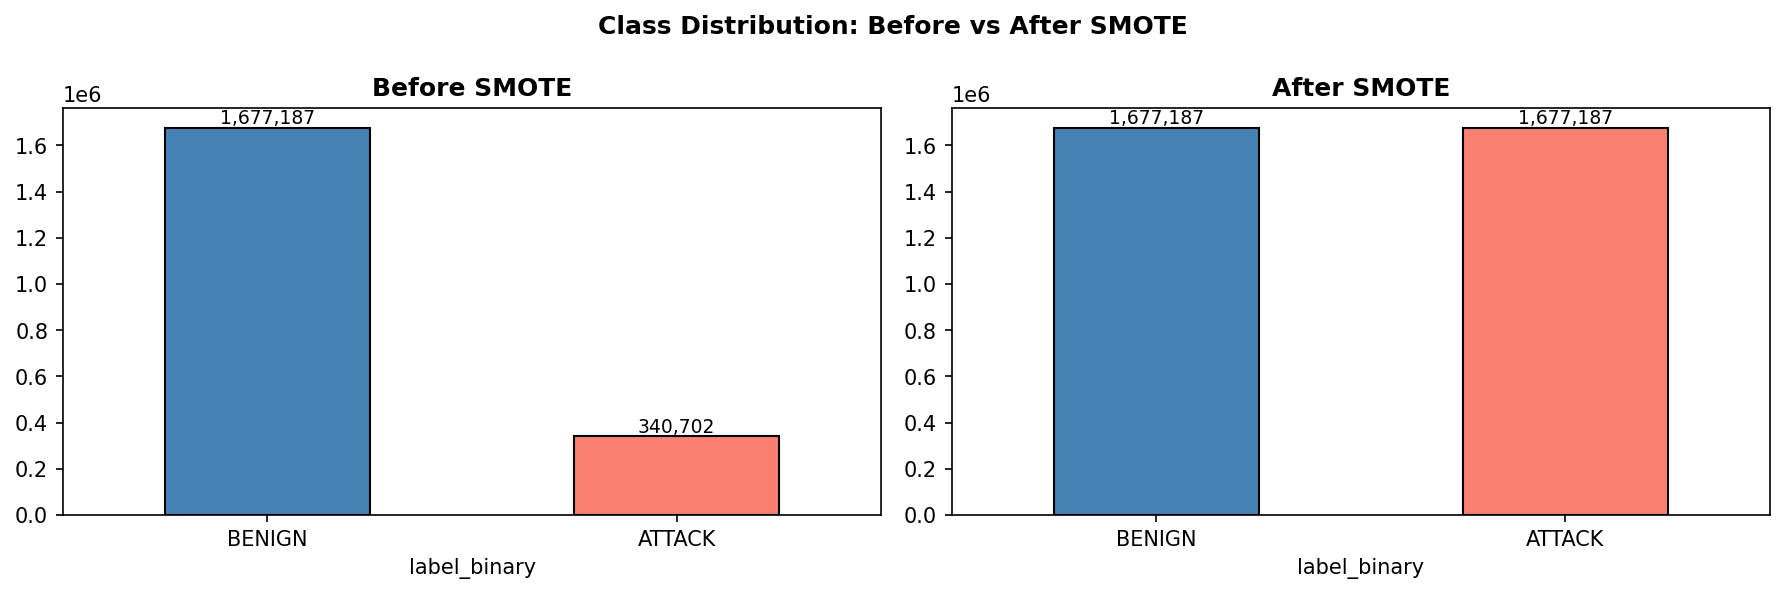

In [17]:
# ── 4.3  SMOTE (applied only to TRAINING data) ───────────────────────
# SMOTE: x_new = x_i + lambda*(x_nn - x_i), lambda~U[0,1]
# Creates synthetic minority samples by interpolation, not duplication.
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
X_train_s, y_train_s = smote.fit_resample(X_train, y_train_bin)

vc_s = pd.Series(y_train_s).value_counts()
print(f"After SMOTE -- BENIGN: {vc_s[0]:,}  |  ATTACK: {vc_s[1]:,}")
print(f"New ratio: {vc_s[0]/vc_s[1]:.2f}:1   Total: {len(X_train_s):,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (data, title) in zip(axes, [
        (y_train_bin,          "Before SMOTE"),
        (pd.Series(y_train_s), "After SMOTE")]):
    vc2 = data.value_counts()
    vc2.plot(kind="bar", ax=ax, color=["steelblue","salmon"], edgecolor="black")
    ax.set_xticklabels(["BENIGN","ATTACK"], rotation=0)
    ax.set_title(title, fontweight="bold")
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height()):,}",
                    (p.get_x()+p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.suptitle("Class Distribution: Before vs After SMOTE", fontweight="bold")
plt.tight_layout()
plt.show()

## PART A – Classification (5 Algorithms)

**Task:** Binary classification — predict whether a network flow is BENIGN (0) or an ATTACK (1).

| # | Algorithm | Type |
|---|-----------|------|
| 1 | Logistic Regression | Linear / Baseline |
| 2 | Decision Tree | Tree-based |
| 3 | Random Forest | Ensemble (Bagging) |
| 4 | XGBoost | Ensemble (Boosting) |
| 5 | K-Nearest Neighbors | Distance-based |

In [18]:
# ── Part A: Evaluation Helper ─────────────────────────────────────────
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, accuracy_score,
    precision_score, recall_score, f1_score,
    roc_curve, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score
)

clf_results = {}

def evaluate_clf(name, model, Xtr, ytr, Xte, yte):
    t0 = time.time()
    model.fit(Xtr, ytr)
    t_train = round(time.time()-t0, 2)
    yp = model.predict(Xte)
    m = {
        "Accuracy" : accuracy_score(yte, yp),
        "Precision": precision_score(yte, yp, zero_division=0),
        "Recall"   : recall_score(yte, yp, zero_division=0),
        "F1-Score" : f1_score(yte, yp, zero_division=0),
        "Train(s)" : t_train,
    }
    entry = {"metrics": m, "model": model, "y_pred": yp}
    if hasattr(model, "predict_proba"):
        yprob = model.predict_proba(Xte)[:,1]
        m["AUC-ROC"] = roc_auc_score(yte, yprob)
        entry["y_prob"] = yprob
    clf_results[name] = entry
    print(f"\n{'='*58}\n  {name}\n{'='*58}")
    for k, v in m.items():
        fmt = f"{v:.4f}" if isinstance(v, float) else str(v)
        print(f"  {k:12s}: {fmt}")
    print()
    print(classification_report(yte, yp, zero_division=0))
    return m

print("Classification evaluation helper ready.")


Classification evaluation helper ready.


In [19]:
# ── A1: Logistic Regression ───────────────────────────────────────────
# Linear model. P(y=1|x) = sigmoid(w^T x + b).
# Baseline – fast, interpretable, probabilistic output.
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                         n_jobs=-1, C=1.0, solver="lbfgs")
evaluate_clf("A1 - Logistic Regression", lr,
             X_train_s, y_train_s, X_test, y_test_bin)



  A1 - Logistic Regression
  Accuracy    : 0.9278
  Precision   : 0.7105
  Recall      : 0.9662
  F1-Score    : 0.8189
  Train(s)    : 27.0600
  AUC-ROC     : 0.9834

              precision    recall  f1-score   support

           0       0.99      0.92      0.95    419297
           1       0.71      0.97      0.82     85176

    accuracy                           0.93    504473
   macro avg       0.85      0.94      0.89    504473
weighted avg       0.94      0.93      0.93    504473



{'Accuracy': 0.9278316183423096,
 'Precision': 0.7105251797940031,
 'Recall': 0.9662111392880623,
 'F1-Score': 0.8188733501490028,
 'Train(s)': 27.06,
 'AUC-ROC': 0.9834414103686541}

In [20]:
# ── A2: Decision Tree ─────────────────────────────────────────────────
# Recursively splits by Gini impurity: G = 1 - sum(p_k^2).
# Highly interpretable; extract IF-THEN rules from the tree.
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=15, min_samples_leaf=10,
                              random_state=RANDOM_STATE, criterion="gini")
evaluate_clf("A2 - Decision Tree", dt,
             X_train_s, y_train_s, X_test, y_test_bin)



  A2 - Decision Tree
  Accuracy    : 0.9986
  Precision   : 0.9924
  Recall      : 0.9992
  F1-Score    : 0.9958
  Train(s)    : 60.5200
  AUC-ROC     : 0.9998

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419297
           1       0.99      1.00      1.00     85176

    accuracy                           1.00    504473
   macro avg       1.00      1.00      1.00    504473
weighted avg       1.00      1.00      1.00    504473



{'Accuracy': 0.9985866438838154,
 'Precision': 0.9924324576439174,
 'Recall': 0.99924861463323,
 'F1-Score': 0.9958288726255872,
 'Train(s)': 60.52,
 'AUC-ROC': 0.9998264105438871}

In [21]:
# ── A3: Random Forest ─────────────────────────────────────────────────
# Ensemble of Decision Trees (Bagging + Feature Randomness).
# Majority vote of 100 trees on bootstrap samples.
# Reduces variance without increasing bias.
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, max_depth=20,
                             min_samples_leaf=5, n_jobs=-1,
                             random_state=RANDOM_STATE,
                             class_weight="balanced")
evaluate_clf("A3 - Random Forest", rf,
             X_train_s, y_train_s, X_test, y_test_bin)



  A3 - Random Forest
  Accuracy    : 0.9989
  Precision   : 0.9940
  Recall      : 0.9994
  F1-Score    : 0.9967
  Train(s)    : 209.7900
  AUC-ROC     : 1.0000

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419297
           1       0.99      1.00      1.00     85176

    accuracy                           1.00    504473
   macro avg       1.00      1.00      1.00    504473
weighted avg       1.00      1.00      1.00    504473



{'Accuracy': 0.9988839838802077,
 'Precision': 0.9940212758503918,
 'Recall': 0.9994012397858552,
 'F1-Score': 0.9967039979392669,
 'Train(s)': 209.79,
 'AUC-ROC': 0.9999583908192109}

In [22]:
# ── A4: XGBoost ───────────────────────────────────────────────────────
# Gradient Boosting: each tree corrects errors of the previous ensemble.
# Adds L1/L2 regularisation, column subsampling, histogram splits.
import xgboost as xgb

xgb_clf = xgb.XGBClassifier(
    n_estimators=200, max_depth=8, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    eval_metric="logloss", random_state=RANDOM_STATE,
    n_jobs=-1, tree_method="hist")
evaluate_clf("A4 - XGBoost", xgb_clf,
             X_train_s, y_train_s, X_test, y_test_bin)



  A4 - XGBoost
  Accuracy    : 0.9990
  Precision   : 0.9944
  Recall      : 0.9997
  F1-Score    : 0.9970
  Train(s)    : 26.2500
  AUC-ROC     : 1.0000

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419297
           1       0.99      1.00      1.00     85176

    accuracy                           1.00    504473
   macro avg       1.00      1.00      1.00    504473
weighted avg       1.00      1.00      1.00    504473



{'Accuracy': 0.9989949908121941,
 'Precision': 0.994394422450338,
 'Recall': 0.9996830092983939,
 'F1-Score': 0.9970317028190041,
 'Train(s)': 26.25,
 'AUC-ROC': 0.999968478392254}

In [23]:
# ── A5: K-Nearest Neighbors ───────────────────────────────────────────
# Lazy learner: classify by majority vote of k=7 nearest neighbours.
# Euclidean distance -> StandardScaler is essential here.
from sklearn.neighbors import KNeighborsClassifier

SMPL = 80_000
rng  = np.random.default_rng(RANDOM_STATE)
idx  = rng.choice(len(X_train_s), min(SMPL, len(X_train_s)), replace=False)
Xk   = X_train_s.iloc[idx]
yk   = np.array(y_train_s)[idx]

knn = KNeighborsClassifier(n_neighbors=7, n_jobs=-1, algorithm="ball_tree")
evaluate_clf("A5 - K-Nearest Neighbors", knn, Xk, yk, X_test, y_test_bin)



  A5 - K-Nearest Neighbors
  Accuracy    : 0.9828
  Precision   : 0.9131
  Recall      : 0.9923
  F1-Score    : 0.9510
  Train(s)    : 0.2500
  AUC-ROC     : 0.9966

              precision    recall  f1-score   support

           0       1.00      0.98      0.99    419297
           1       0.91      0.99      0.95     85176

    accuracy                           0.98    504473
   macro avg       0.96      0.99      0.97    504473
weighted avg       0.98      0.98      0.98    504473



{'Accuracy': 0.9827503156759628,
 'Precision': 0.9130871613154142,
 'Recall': 0.9922865595942519,
 'F1-Score': 0.9510408461798132,
 'Train(s)': 0.25,
 'AUC-ROC': 0.9965821673590409}

## PART A – Classification Evaluation

In [24]:
# ── Part A: Comparison Table ──────────────────────────────────────────
rows_a = [dict(Model=n, **r["metrics"]) for n, r in clf_results.items()]
cdf_a = pd.DataFrame(rows_a).set_index("Model")
print("=== PART A: CLASSIFICATION MODEL COMPARISON ===")
display(cdf_a)


=== PART A: CLASSIFICATION MODEL COMPARISON ===


,Accuracy,Precision,Recall,F1-Score,Train(s),AUC-ROC
Model,,,,,,
A1 - Logistic Regression,0.9278,0.7105,0.9662,0.8189,27.0600,0.9834
A2 - Decision Tree,0.9986,0.9924,0.9992,0.9958,60.5200,0.9998
A3 - Random Forest,0.9989,0.9940,0.9994,0.9967,209.7900,1.0000
A4 - XGBoost,0.9990,0.9944,0.9997,0.9970,26.2500,1.0000
A5 - K-Nearest Neighbors,0.9828,0.9131,0.9923,0.9510,0.2500,0.9966


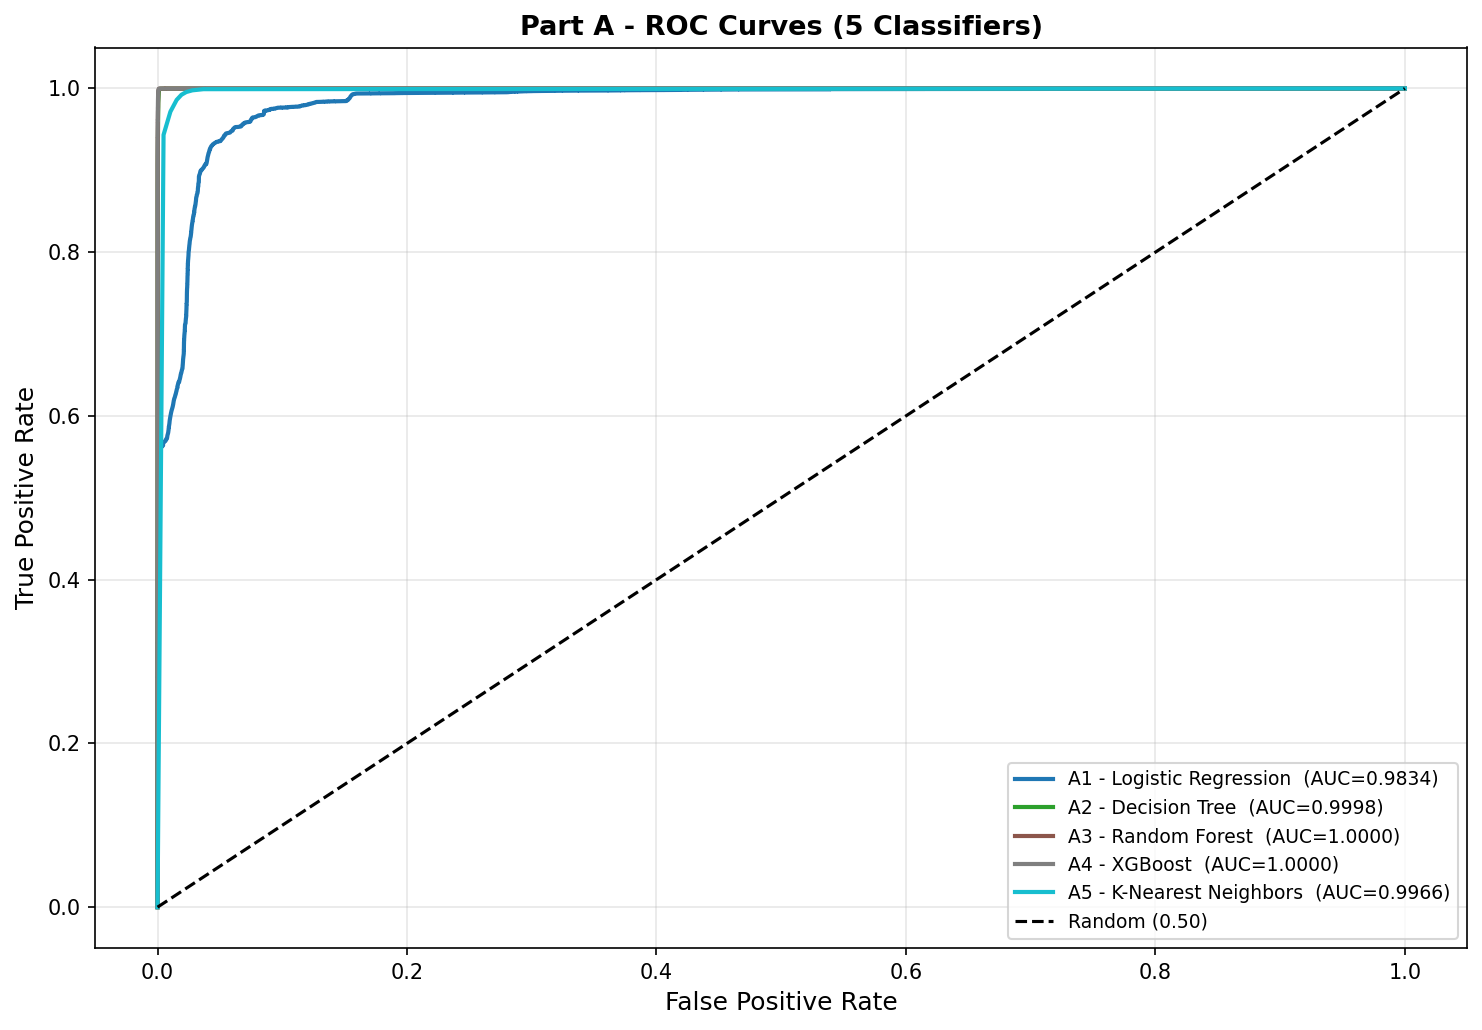

In [25]:
# ── Part A: ROC Curves ────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))
colors = plt.cm.tab10(np.linspace(0, 1, len(clf_results)))
for (name, res), color in zip(clf_results.items(), colors):
    if "y_prob" in res:
        fpr, tpr, _ = roc_curve(y_test_bin, res["y_prob"])
        auc = res["metrics"].get("AUC-ROC", 0)
        ax.plot(fpr, tpr, label=f"{name}  (AUC={auc:.4f})", color=color, lw=2)
ax.plot([0,1],[0,1],"k--",lw=1.5,label="Random (0.50)")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("Part A - ROC Curves (5 Classifiers)", fontweight="bold", fontsize=13)
ax.legend(loc="lower right", fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

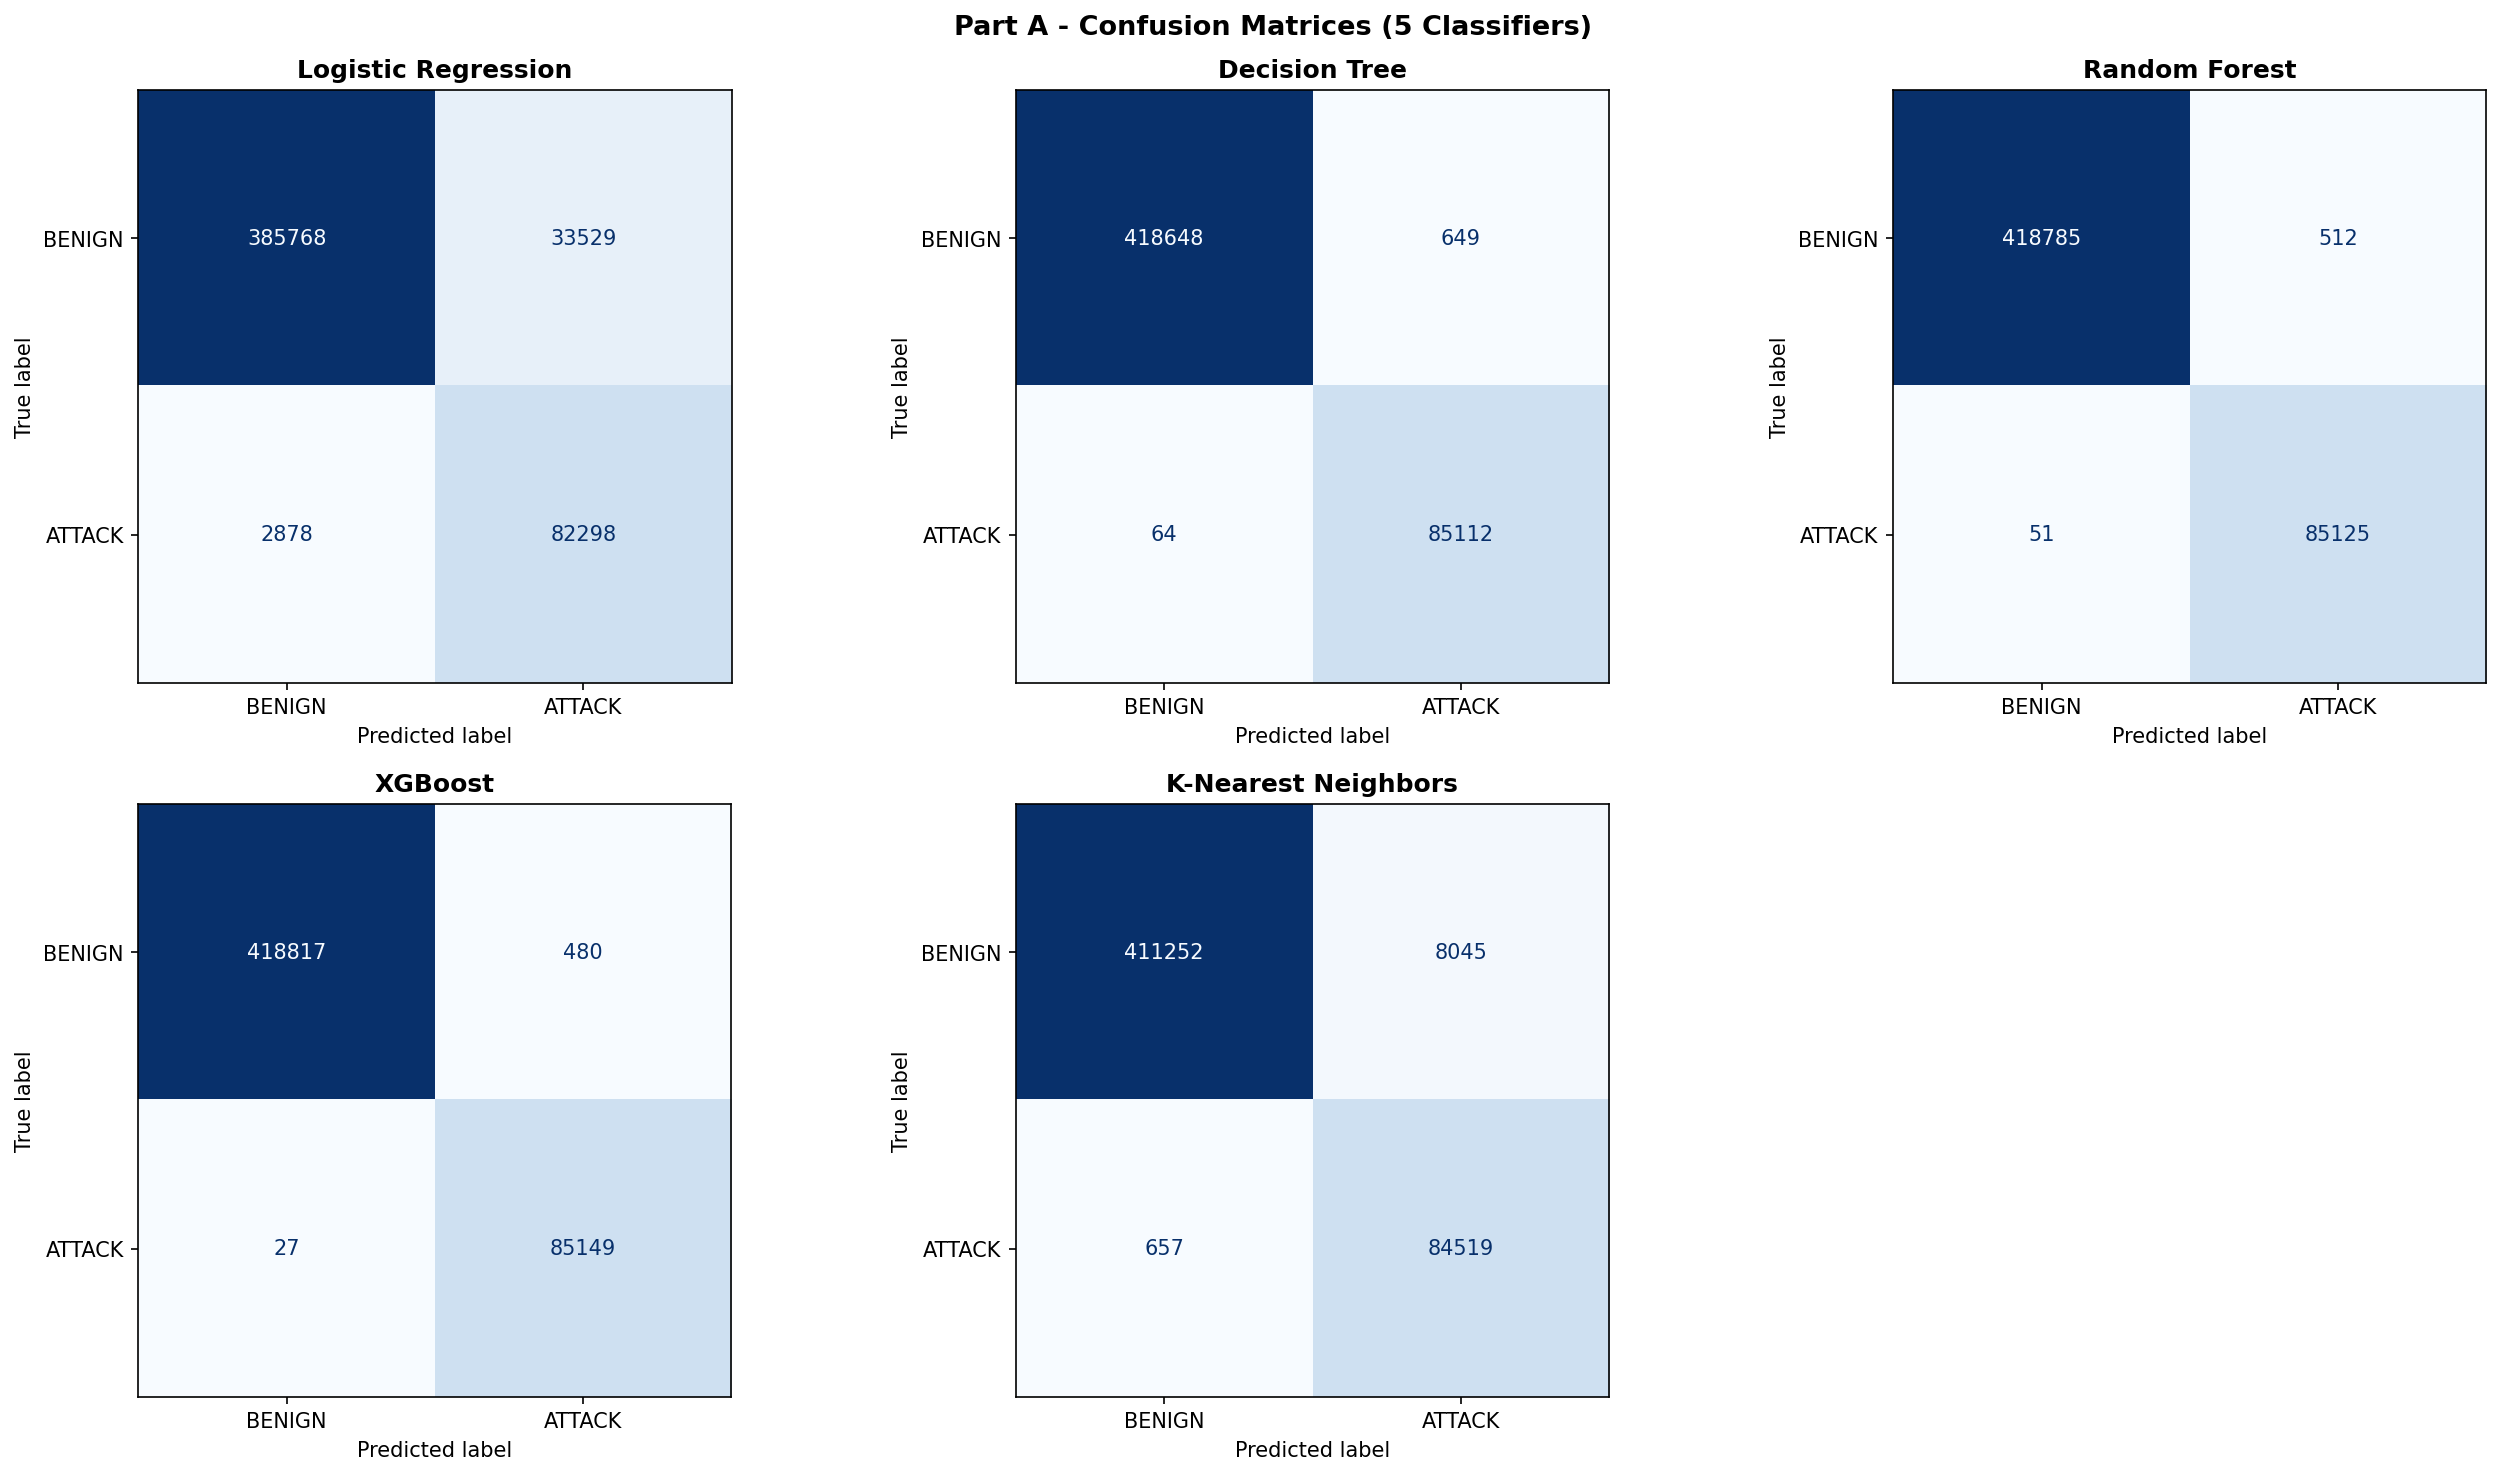

In [26]:
# ── Part A: Confusion Matrices ────────────────────────────────────────
n_clfs = len(clf_results)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for ax, (name, res) in zip(axes, clf_results.items()):
    cm = confusion_matrix(y_test_bin, res["y_pred"])
    ConfusionMatrixDisplay(cm, display_labels=["BENIGN","ATTACK"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(name.split(" - ")[1], fontweight="bold")
for ax in axes[n_clfs:]:
    ax.set_visible(False)
plt.suptitle("Part A - Confusion Matrices (5 Classifiers)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

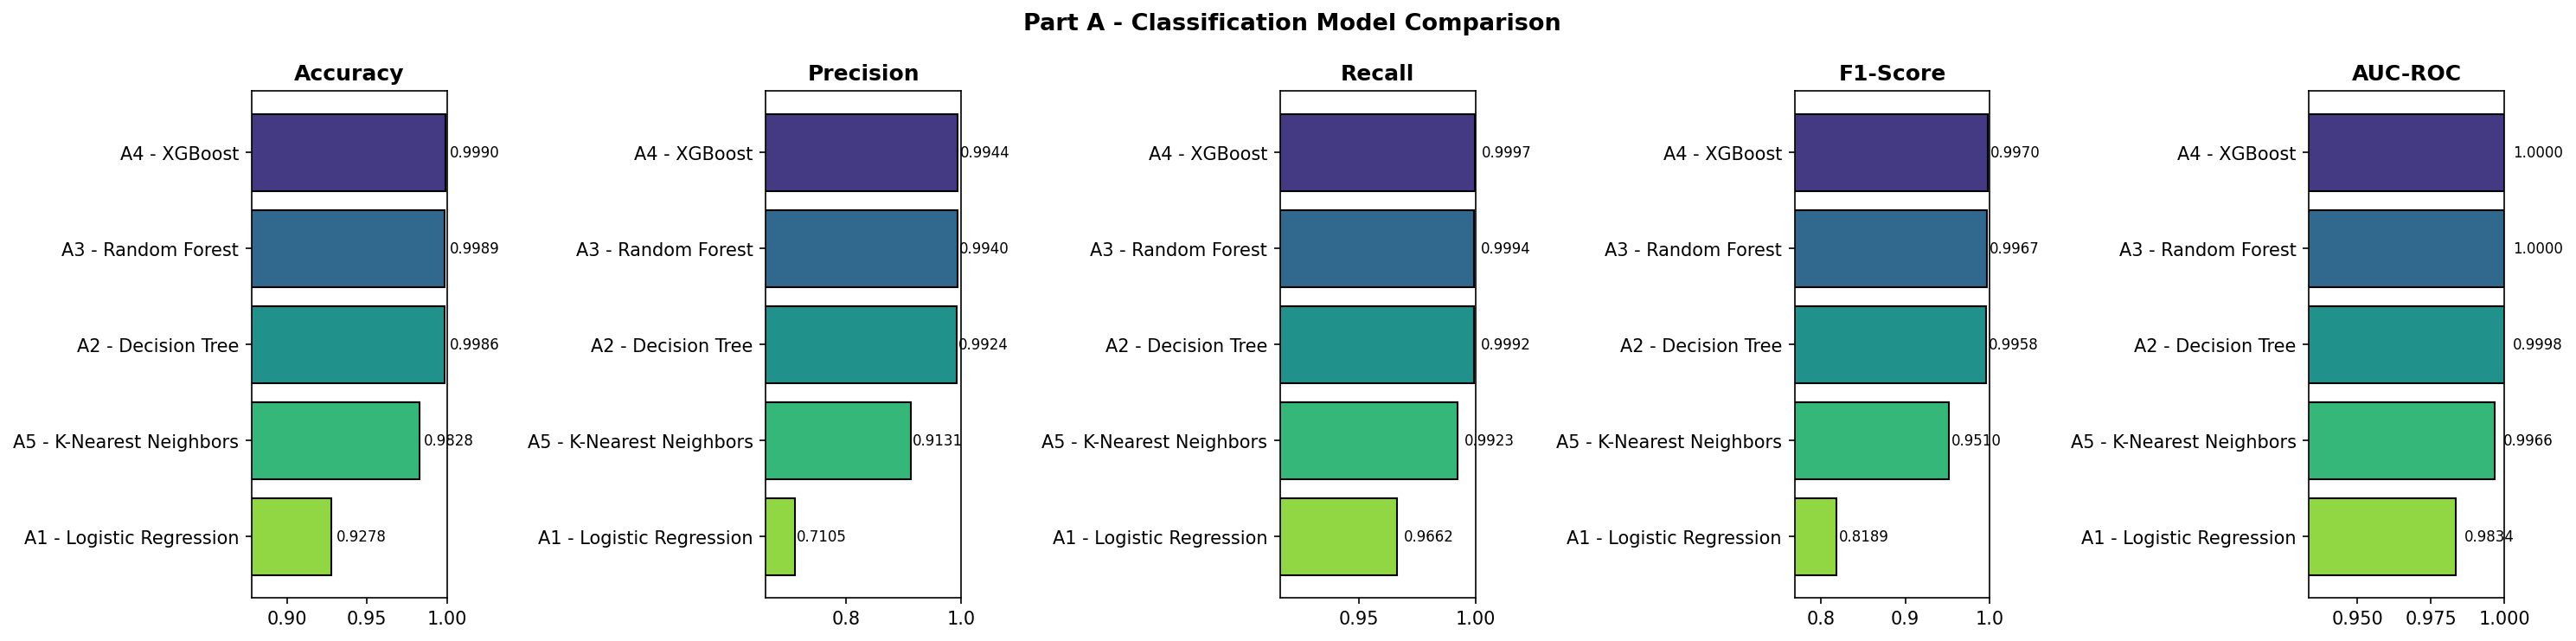

In [27]:
# ── Part A: Metric Bar Chart ──────────────────────────────────────────
metric_cols = [m for m in ["Accuracy","Precision","Recall","F1-Score","AUC-ROC"]
               if m in cdf_a.columns]
fig, axes = plt.subplots(1, len(metric_cols), figsize=(20, 5))
for ax, metric in zip(axes, metric_cols):
    data = cdf_a[metric].sort_values(ascending=False)
    bars = ax.barh(data.index, data.values,
                   color=sns.color_palette("viridis", len(data)), edgecolor="black")
    ax.set_title(metric, fontweight="bold")
    ax.set_xlim(max(0, data.min()-0.05), 1.0)
    for bar, val in zip(bars, data.values):
        ax.text(val+0.003, bar.get_y()+bar.get_height()/2,
                f"{val:.4f}", va="center", fontsize=8)
    ax.invert_yaxis()
plt.suptitle("Part A - Classification Model Comparison", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

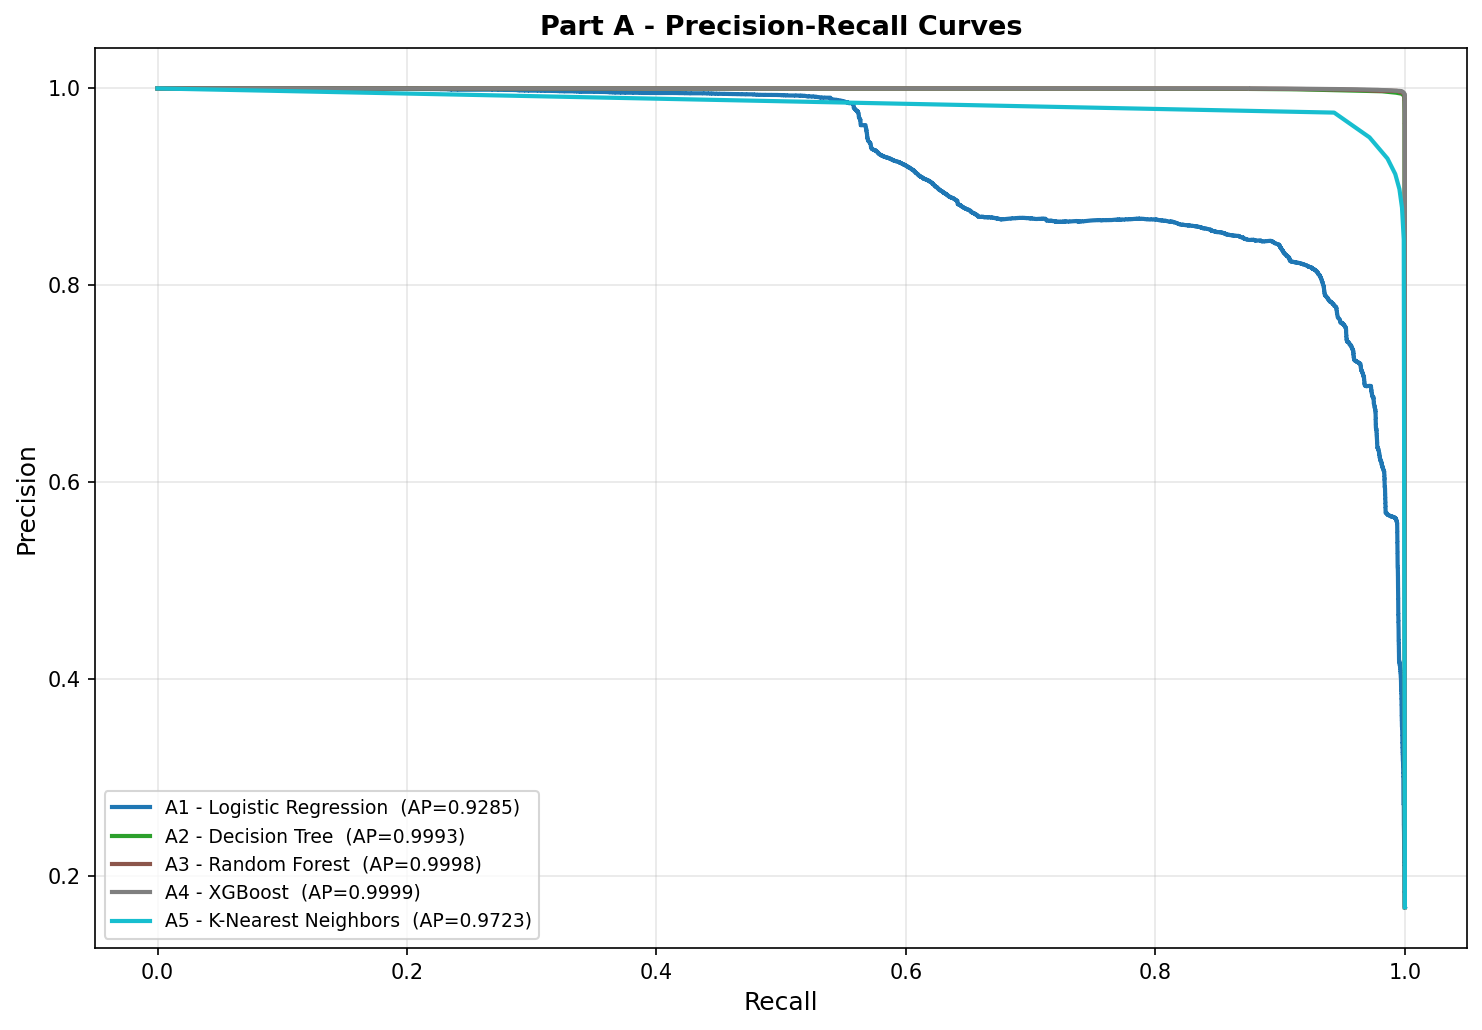

In [28]:
# ── Part A: Precision-Recall Curves ──────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))
colors = plt.cm.tab10(np.linspace(0, 1, len(clf_results)))
for (name, res), color in zip(clf_results.items(), colors):
    if "y_prob" in res:
        prec, rec, _ = precision_recall_curve(y_test_bin, res["y_prob"])
        ap = average_precision_score(y_test_bin, res["y_prob"])
        ax.plot(rec, prec, label=f"{name}  (AP={ap:.4f})", color=color, lw=2)
ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Part A - Precision-Recall Curves", fontweight="bold", fontsize=13)
ax.legend(loc="lower left", fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# ── Part A: Best Classifier ───────────────────────────────────────────
best_clf = cdf_a["F1-Score"].idxmax()
print(f"Best Classifier (F1-Score): {best_clf}")
print(f"  F1      = {cdf_a.loc[best_clf,'F1-Score']:.4f}")
print(f"  Accuracy= {cdf_a.loc[best_clf,'Accuracy']:.4f}")
if "AUC-ROC" in cdf_a.columns:
    print(f"  AUC-ROC = {cdf_a.loc[best_clf,'AUC-ROC']:.4f}")


Best Classifier (F1-Score): A4 - XGBoost
  F1      = 0.9970
  Accuracy= 0.9990
  AUC-ROC = 1.0000


## PART B – Regression (10 Algorithms)

**Regression Target:** `Flow Duration` (microseconds) — continuous variable representing
how long a network connection lasted. Attacks often exhibit anomalous flow durations.

**Why regression on IDS data?**
- Predicting flow characteristics helps understand network behaviour
- Regression models can predict severity scores or anomaly magnitudes
- Provides complementary analysis to classification

| # | Algorithm | Category |
|---|-----------|----------|
| 1 | Linear Regression | Linear |
| 2 | Ridge Regression | Linear + L2 Regularisation |
| 3 | Lasso Regression | Linear + L1 Regularisation |
| 4 | ElasticNet | Linear + L1+L2 Regularisation |
| 5 | Decision Tree Regressor | Tree-based |
| 6 | Random Forest Regressor | Ensemble (Bagging) |
| 7 | Gradient Boosting Regressor | Ensemble (Boosting) |
| 8 | XGBoost Regressor | Optimised Boosting |
| 9 | LightGBM Regressor | Leaf-wise Boosting |
| 10 | K-Nearest Neighbors Regressor | Distance-based |

=== PART B: REGRESSION SETUP ===
Regression target: Flow Duration
Regression features: 30


X_reg shape : (2522362, 30)
y_reg range : [0.00, 18.60]  (log1p scale)


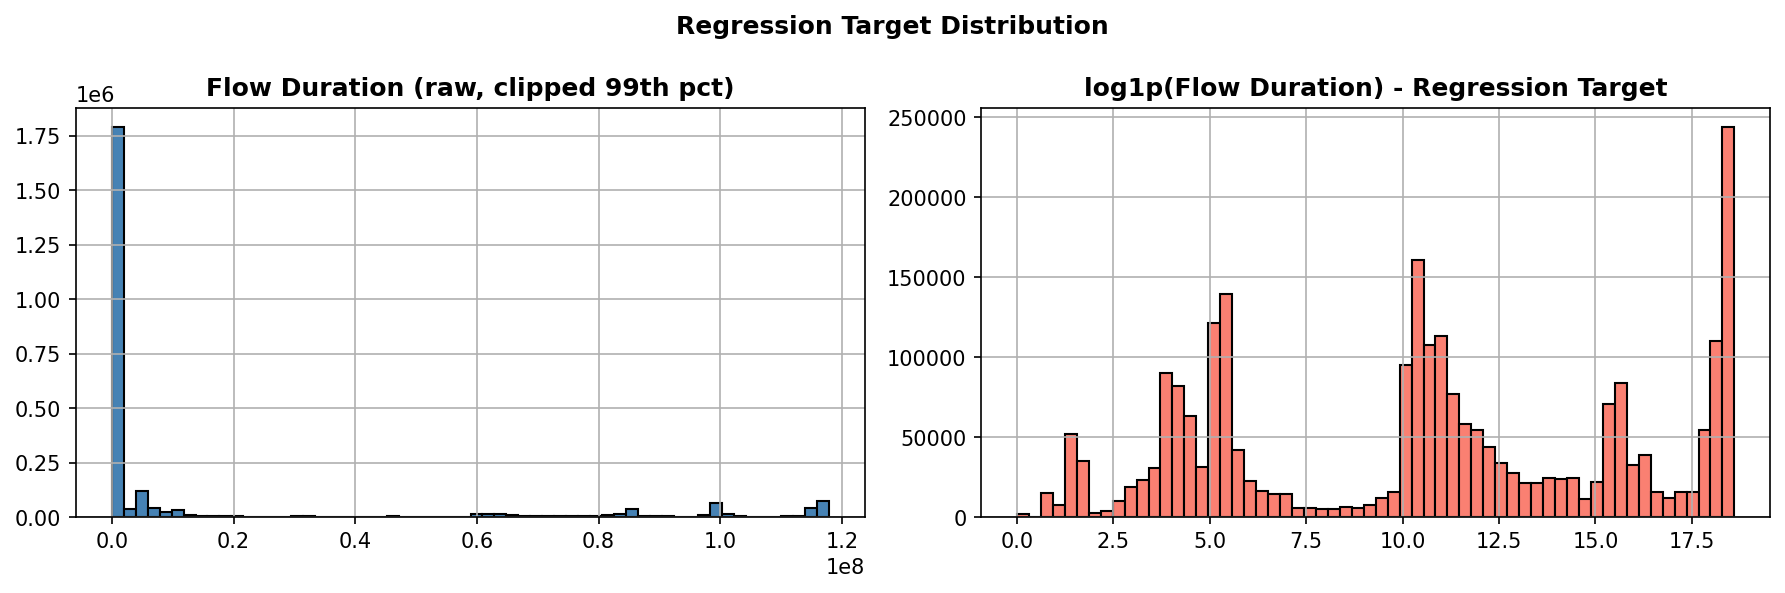

In [30]:
# ── Part B: Regression Setup ──────────────────────────────────────────
# Target: Flow Duration (log-transformed for normality)
# Features: same 30 selected features (excluding Flow Duration itself)

print("=== PART B: REGRESSION SETUP ===")

REG_FEAT_COL = "Flow Duration"

# Ensure Flow Duration column exists
if REG_FEAT_COL not in df.columns:
    # Use the raw column (may still be in df even if not in selected_features)
    avail = [c for c in df.columns if "duration" in c.lower() or "Duration" in c]
    REG_FEAT_COL = avail[0] if avail else None
    print(f"Using regression target: {REG_FEAT_COL}")
else:
    print(f"Regression target: {REG_FEAT_COL}")

# Build regression feature set (exclude the target from features)
reg_features = [c for c in selected_features if c != REG_FEAT_COL]
print(f"Regression features: {len(reg_features)}")

# Target: log1p(Flow Duration) for better distribution
y_reg_raw = df[REG_FEAT_COL].clip(lower=0)
y_reg     = np.log1p(y_reg_raw).values  # log-transform

# Feature matrix
X_reg = df[reg_features].copy()
scaler_reg = StandardScaler()
X_reg_scaled = scaler_reg.fit_transform(X_reg)

print(f"X_reg shape : {X_reg_scaled.shape}")
print(f"y_reg range : [{y_reg.min():.2f}, {y_reg.max():.2f}]  (log1p scale)")

# Distribution of target
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.Series(y_reg_raw).clip(upper=y_reg_raw.quantile(0.99)).hist(
    ax=axes[0], bins=60, color="steelblue", edgecolor="black")
axes[0].set_title("Flow Duration (raw, clipped 99th pct)", fontweight="bold")
pd.Series(y_reg).hist(ax=axes[1], bins=60, color="salmon", edgecolor="black")
axes[1].set_title("log1p(Flow Duration) - Regression Target", fontweight="bold")
plt.suptitle("Regression Target Distribution", fontweight="bold")
plt.tight_layout()
plt.show()

In [31]:
# ── Part B: Train/Test Split for Regression ───────────────────────────
from sklearn.model_selection import train_test_split

# Use a manageable sample (regression is memory-intensive)
REG_SAMPLE = 200_000
if len(X_reg_scaled) > REG_SAMPLE:
    ridx = np.random.default_rng(RANDOM_STATE).choice(
           len(X_reg_scaled), REG_SAMPLE, replace=False)
    Xr   = X_reg_scaled[ridx]
    yr   = y_reg[ridx]
    print(f"Using {REG_SAMPLE:,} sample for regression.")
else:
    Xr, yr = X_reg_scaled, y_reg

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=RANDOM_STATE)
print(f"Reg Train: {Xr_train.shape[0]:,}  |  Reg Test: {Xr_test.shape[0]:,}")


Using 200,000 sample for regression.
Reg Train: 160,000  |  Reg Test: 40,000


In [32]:
# ── Part B: Regression Evaluation Helper ─────────────────────────────
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

reg_results = {}

def evaluate_reg(name, model, Xtr, ytr, Xte, yte):
    t0 = time.time()
    model.fit(Xtr, ytr)
    t_train = round(time.time()-t0, 2)
    yp = model.predict(Xte)

    mae  = mean_absolute_error(yte, yp)
    mse  = mean_squared_error(yte, yp)
    rmse = np.sqrt(mse)
    r2   = r2_score(yte, yp)

    m = {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2 Score": r2, "Train(s)": t_train}
    reg_results[name] = {"metrics": m, "model": model, "y_pred": yp}

    print(f"\n{'='*58}\n  {name}\n{'='*58}")
    print(f"  MAE      : {mae:.4f}")
    print(f"  MSE      : {mse:.4f}")
    print(f"  RMSE     : {rmse:.4f}")
    print(f"  R2 Score : {r2:.4f}")
    print(f"  Train(s) : {t_train}")
    return m

print("Regression evaluation helper ready.")


Regression evaluation helper ready.


In [33]:
# ── B1: Linear Regression ─────────────────────────────────────────────
# Baseline: y = w0 + w1*x1 + ... + wn*xn
# Minimises Sum of Squared Errors (SSE). No regularisation.
from sklearn.linear_model import LinearRegression

lr_reg = LinearRegression(n_jobs=-1)
evaluate_reg("B1 - Linear Regression", lr_reg,
             Xr_train, yr_train, Xr_test, yr_test)



  B1 - Linear Regression


  MAE      : 2.3048
  MSE      : 8.0958
  RMSE     : 2.8453
  R2 Score : 0.7091
  Train(s) : 0.09


{'MAE': 2.304759270244727,
 'MSE': 8.0957882052793,
 'RMSE': 2.845309861030833,
 'R2 Score': 0.7090504943327639,
 'Train(s)': 0.09}

In [34]:
# ── B2: Ridge Regression (L2 Regularisation) ──────────────────────────
# Loss = SSE + alpha * sum(w_i^2)
# Shrinks coefficients toward zero. Prevents overfitting. No sparsity.
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)
evaluate_reg("B2 - Ridge Regression", ridge,
             Xr_train, yr_train, Xr_test, yr_test)



  B2 - Ridge Regression


  MAE      : 2.3047
  MSE      : 8.0958
  RMSE     : 2.8453
  R2 Score : 0.7090
  Train(s) : 0.04


{'MAE': 2.3047270515550213,
 'MSE': 8.095821112008986,
 'RMSE': 2.845315643651682,
 'R2 Score': 0.7090493117182373,
 'Train(s)': 0.04}

In [35]:
# ── B3: Lasso Regression (L1 Regularisation) ──────────────────────────
# Loss = SSE + alpha * sum(|w_i|)
# Produces sparse solutions (many weights -> 0). Automatic feature selection.
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.01, max_iter=2000)
evaluate_reg("B3 - Lasso Regression", lasso,
             Xr_train, yr_train, Xr_test, yr_test)



  B3 - Lasso Regression
  MAE      : 2.3049
  MSE      : 8.1930
  RMSE     : 2.8623
  R2 Score : 0.7056
  Train(s) : 2.9


{'MAE': 2.304914726548703,
 'MSE': 8.19303541054809,
 'RMSE': 2.862347884263562,
 'R2 Score': 0.7055555874030071,
 'Train(s)': 2.9}

In [36]:
# ── B4: ElasticNet (L1 + L2) ──────────────────────────────────────────
# Loss = SSE + alpha*l1_ratio*|w| + alpha*(1-l1_ratio)*w^2
# Combines sparsity (Lasso) + stability (Ridge). Best of both worlds.
from sklearn.linear_model import ElasticNet

enet = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=2000)
evaluate_reg("B4 - ElasticNet", enet,
             Xr_train, yr_train, Xr_test, yr_test)



  B4 - ElasticNet
  MAE      : 2.3107
  MSE      : 8.2489
  RMSE     : 2.8721
  R2 Score : 0.7035
  Train(s) : 2.67


{'MAE': 2.310711761389796,
 'MSE': 8.24885442643353,
 'RMSE': 2.872081897584665,
 'R2 Score': 0.7035495424489023,
 'Train(s)': 2.67}

In [37]:
# ── B5: Decision Tree Regressor ───────────────────────────────────────
# Splits feature space by minimising MSE at each node.
# Predicts the mean target value in each leaf.
from sklearn.tree import DecisionTreeRegressor

dt_reg = DecisionTreeRegressor(max_depth=15, min_samples_leaf=10,
                                random_state=RANDOM_STATE)
evaluate_reg("B5 - Decision Tree Regressor", dt_reg,
             Xr_train, yr_train, Xr_test, yr_test)



  B5 - Decision Tree Regressor
  MAE      : 0.0141
  MSE      : 0.0056
  RMSE     : 0.0750
  R2 Score : 0.9998
  Train(s) : 1.69


{'MAE': 0.014091387199296182,
 'MSE': 0.005628430972299234,
 'RMSE': 0.07502286966185201,
 'R2 Score': 0.9997977233139567,
 'Train(s)': 1.69}

In [38]:
# ── B6: Random Forest Regressor ───────────────────────────────────────
# Ensemble of Decision Tree Regressors (Bagging).
# Final prediction = average of all tree predictions. Reduces variance.
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(n_estimators=100, max_depth=20,
                                min_samples_leaf=5,
                                random_state=RANDOM_STATE, n_jobs=-1)
evaluate_reg("B6 - Random Forest Regressor", rf_reg,
             Xr_train, yr_train, Xr_test, yr_test)



  B6 - Random Forest Regressor
  MAE      : 0.0078
  MSE      : 0.0022
  RMSE     : 0.0467
  R2 Score : 0.9999
  Train(s) : 12.89


{'MAE': 0.007842672611027359,
 'MSE': 0.0021799388213533575,
 'RMSE': 0.04668981496379438,
 'R2 Score': 0.9999216565322147,
 'Train(s)': 12.89}

In [39]:
# ── B7: Gradient Boosting Regressor ──────────────────────────────────
# Sequential ensemble: each tree fits residuals of the previous model.
# F_m(x) = F_{m-1}(x) + eta * h_m(x)  where h_m minimises MSE on residuals.
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(n_estimators=200, max_depth=5,
                                  learning_rate=0.1, subsample=0.8,
                                  random_state=RANDOM_STATE)
evaluate_reg("B7 - Gradient Boosting Regressor", gbr,
             Xr_train, yr_train, Xr_test, yr_test)



  B7 - Gradient Boosting Regressor
  MAE      : 0.0321
  MSE      : 0.0041
  RMSE     : 0.0638
  R2 Score : 0.9999
  Train(s) : 144.15


{'MAE': 0.03213617695883234,
 'MSE': 0.004075846645478545,
 'RMSE': 0.06384235776879285,
 'R2 Score': 0.9998535206780849,
 'Train(s)': 144.15}

In [40]:
# ── B8: XGBoost Regressor ─────────────────────────────────────────────
# Extreme Gradient Boosting for regression.
# Adds L1/L2 regularisation, histogram splits, column subsampling.
# Faster and more accurate than standard GBR for large datasets.
import xgboost as xgb

xgb_reg = xgb.XGBRegressor(
    n_estimators=200, max_depth=8, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
    eval_metric="rmse")
evaluate_reg("B8 - XGBoost Regressor", xgb_reg,
             Xr_train, yr_train, Xr_test, yr_test)



  B8 - XGBoost Regressor
  MAE      : 0.0169
  MSE      : 0.0013
  RMSE     : 0.0364
  R2 Score : 1.0000
  Train(s) : 1.3


{'MAE': 0.01687373466118927,
 'MSE': 0.0013213995994316298,
 'RMSE': 0.036351060499408124,
 'R2 Score': 0.9999525110402477,
 'Train(s)': 1.3}

In [41]:
# ── B9: LightGBM Regressor ────────────────────────────────────────────
# Microsoft's leaf-wise gradient boosting. Much faster than XGBoost
# on large datasets via GOSS (gradient-based one-side sampling).
import lightgbm as lgb

lgb_reg = lgb.LGBMRegressor(
    n_estimators=200, max_depth=10, learning_rate=0.05,
    num_leaves=63, subsample=0.8, colsample_bytree=0.8,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
evaluate_reg("B9 - LightGBM Regressor", lgb_reg,
             Xr_train, yr_train, Xr_test, yr_test)



  B9 - LightGBM Regressor
  MAE      : 0.0245
  MSE      : 0.0028
  RMSE     : 0.0527
  R2 Score : 0.9999
  Train(s) : 1.1


{'MAE': 0.02445615711314909,
 'MSE': 0.002782532358978778,
 'RMSE': 0.0527497143023427,
 'R2 Score': 0.9999000002972138,
 'Train(s)': 1.1}

In [42]:
# ── B10: K-Nearest Neighbors Regressor ───────────────────────────────
# Predicts the MEAN target value of k=7 nearest neighbours.
# No explicit training; all computation at prediction time.
# Very sensitive to scale -> StandardScaler is essential.
from sklearn.neighbors import KNeighborsRegressor

REG_SMPL = 60_000
rng2 = np.random.default_rng(RANDOM_STATE)
ri   = rng2.choice(len(Xr_train), min(REG_SMPL, len(Xr_train)), replace=False)
Xrk, yrk = Xr_train[ri], yr_train[ri]

knn_reg = KNeighborsRegressor(n_neighbors=7, n_jobs=-1, algorithm="ball_tree")
evaluate_reg("B10 - KNN Regressor", knn_reg,
             Xrk, yrk, Xr_test, yr_test)



  B10 - KNN Regressor
  MAE      : 0.2644
  MSE      : 0.4026
  RMSE     : 0.6345
  R2 Score : 0.9855
  Train(s) : 0.17


{'MAE': 0.2643609248339376,
 'MSE': 0.4025870454737221,
 'RMSE': 0.6344974747575612,
 'R2 Score': 0.9855316741373953,
 'Train(s)': 0.17}

## PART B – Regression Evaluation

In [43]:
# ── Part B: Comparison Table ──────────────────────────────────────────
rows_r = [dict(Model=n, **r["metrics"]) for n, r in reg_results.items()]
rdf = pd.DataFrame(rows_r).set_index("Model")
print("=== PART B: REGRESSION MODEL COMPARISON ===")
display(rdf)


=== PART B: REGRESSION MODEL COMPARISON ===


,MAE,MSE,RMSE,R2 Score,Train(s)
Model,,,,,
B1 - Linear Regression,2.3048,8.0958,2.8453,0.7091,0.0900
B2 - Ridge Regression,2.3047,8.0958,2.8453,0.7090,0.0400
B3 - Lasso Regression,2.3049,8.1930,2.8623,0.7056,2.9000
B4 - ElasticNet,2.3107,8.2489,2.8721,0.7035,2.6700
B5 - Decision Tree Regressor,0.0141,0.0056,0.0750,0.9998,1.6900
B6 - Random Forest Regressor,0.0078,0.0022,0.0467,0.9999,12.8900
B7 - Gradient Boosting Regressor,0.0321,0.0041,0.0638,0.9999,144.1500
B8 - XGBoost Regressor,0.0169,0.0013,0.0364,1.0000,1.3000
B9 - LightGBM Regressor,0.0245,0.0028,0.0527,0.9999,1.1000


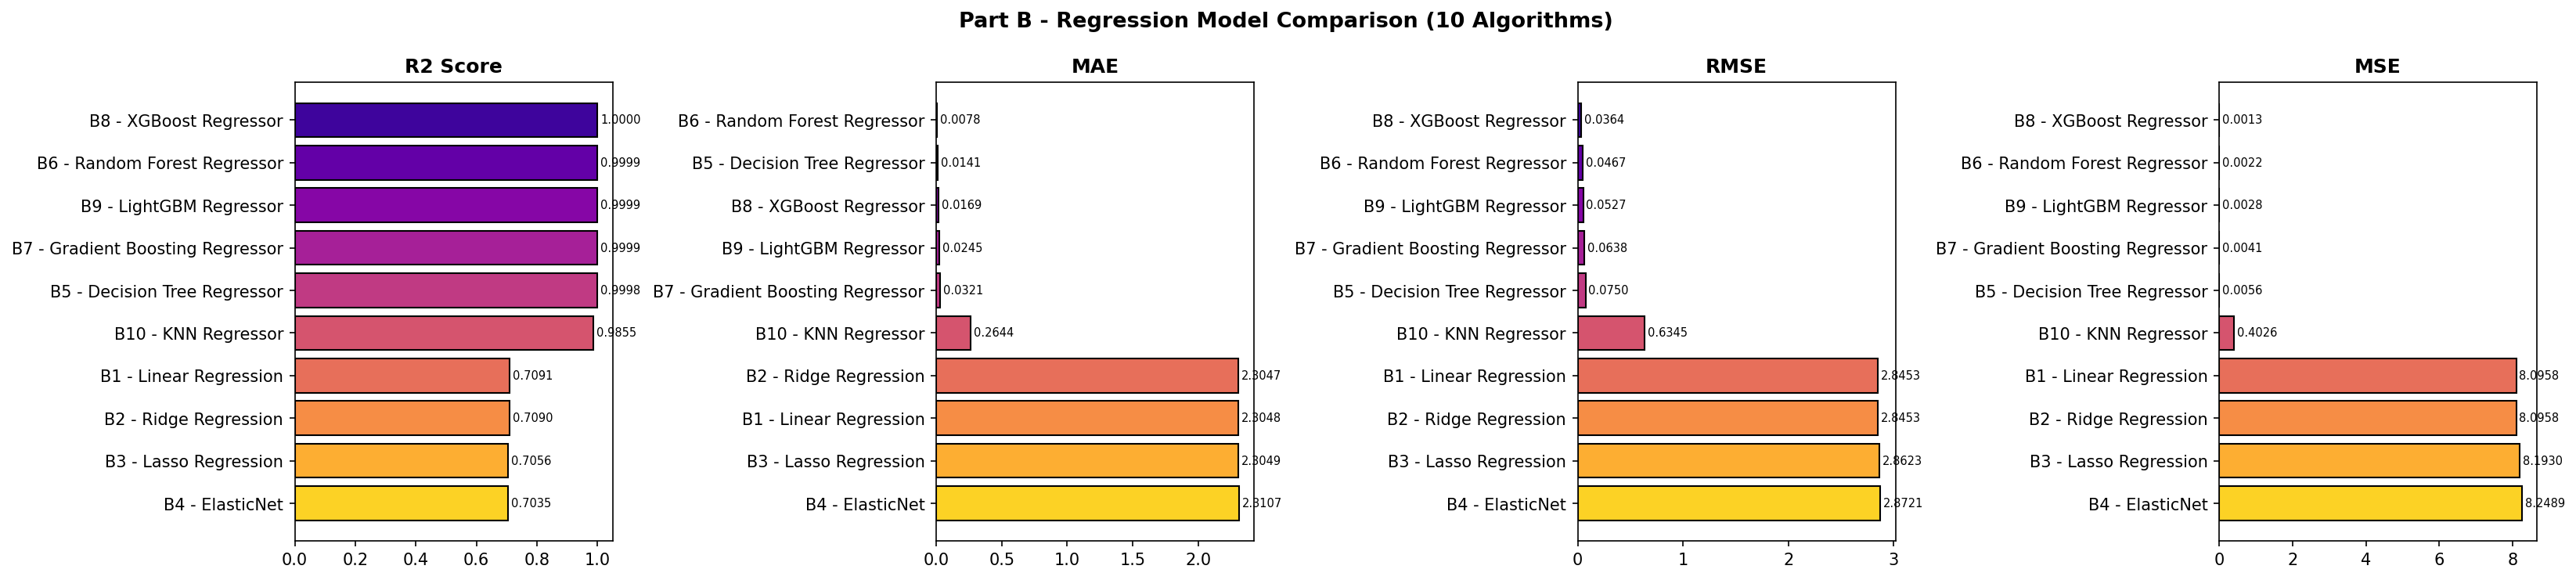

In [44]:
# ── Part B: R2 Score Bar Chart ────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, metric in zip(axes, ["R2 Score","MAE","RMSE","MSE"]):
    data = rdf[metric].sort_values(ascending=(metric != "R2 Score"))
    bars = ax.barh(data.index, data.values,
                   color=sns.color_palette("plasma", len(data)), edgecolor="black")
    ax.set_title(metric, fontweight="bold")
    for bar, val in zip(bars, data.values):
        ax.text(val + abs(data.values.max())*0.01,
                bar.get_y()+bar.get_height()/2,
                f"{val:.4f}", va="center", fontsize=7)
    ax.invert_yaxis()
plt.suptitle("Part B - Regression Model Comparison (10 Algorithms)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Best Regression Model (R2): B8 - XGBoost Regressor
  R2   = 1.0000
  RMSE = 0.0364
  MAE  = 0.0169


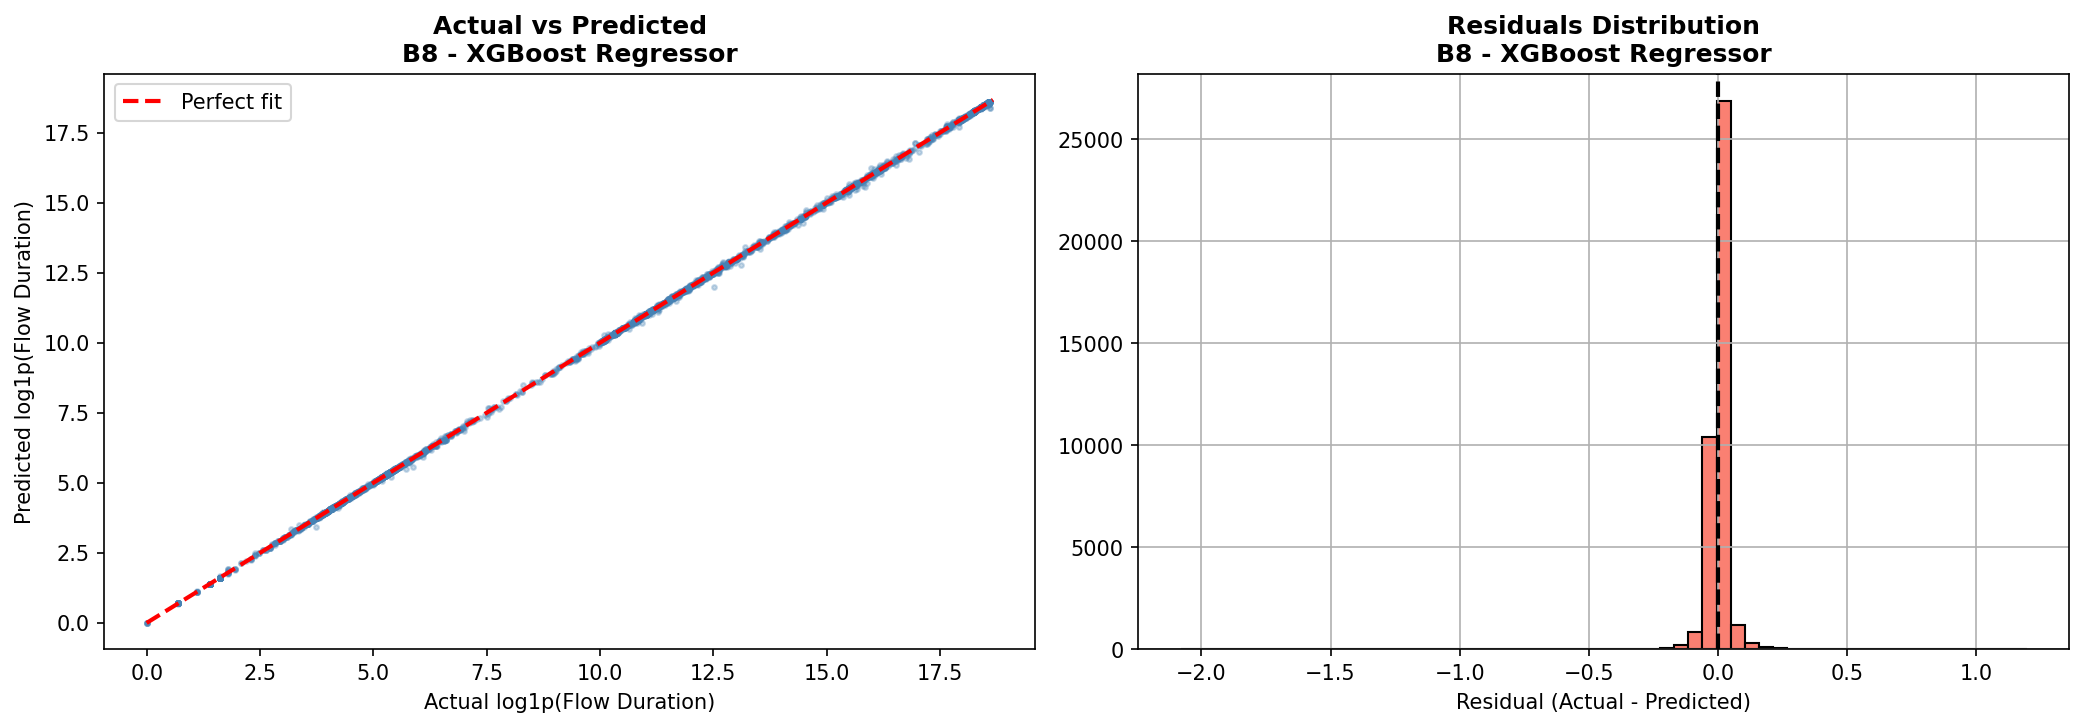

In [45]:
# ── Part B: Actual vs Predicted (Best Regressor) ──────────────────────
best_reg = rdf["R2 Score"].idxmax()
print(f"Best Regression Model (R2): {best_reg}")
print(f"  R2   = {rdf.loc[best_reg,'R2 Score']:.4f}")
print(f"  RMSE = {rdf.loc[best_reg,'RMSE']:.4f}")
print(f"  MAE  = {rdf.loc[best_reg,'MAE']:.4f}")

yp_best = reg_results[best_reg]["y_pred"]
sample_n = min(5000, len(yr_test))
si = np.random.default_rng(RANDOM_STATE).choice(len(yr_test), sample_n, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(yr_test[si], yp_best[si], alpha=0.3, s=5, color="steelblue")
lo = min(yr_test.min(), yp_best.min())
hi = max(yr_test.max(), yp_best.max())
axes[0].plot([lo, hi], [lo, hi], "r--", lw=2, label="Perfect fit")
axes[0].set_xlabel("Actual log1p(Flow Duration)")
axes[0].set_ylabel("Predicted log1p(Flow Duration)")
axes[0].set_title(f"Actual vs Predicted\n{best_reg}", fontweight="bold")
axes[0].legend()

residuals = yr_test - yp_best
pd.Series(residuals).hist(ax=axes[1], bins=60, color="salmon", edgecolor="black")
axes[1].axvline(0, color="k", lw=2, linestyle="--")
axes[1].set_title(f"Residuals Distribution\n{best_reg}", fontweight="bold")
axes[1].set_xlabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

## PHASE 8 – Optional Extension

=== MULTICLASS ATTACK TYPE CLASSIFICATION ===


                          precision    recall  f1-score   support

                  BENIGN       1.00      1.00      1.00    419297
                     Bot       0.23      1.00      0.37       391
                    DDoS       1.00      1.00      1.00     25603
           DoS GoldenEye       0.99      1.00      0.99      2057
                DoS Hulk       0.99      1.00      1.00     34570
        DoS Slowhttptest       0.99      0.99      0.99      1046
           DoS slowloris       0.99      0.99      0.99      1077
             FTP-Patator       1.00      1.00      1.00      1187
              Heartbleed       1.00      1.00      1.00         2
            Infiltration       1.00      0.71      0.83         7
                PortScan       0.99      1.00      0.99     18164
             SSH-Patator       1.00      1.00      1.00       644
  Web Attack-Brute Force       0.80      0.54      0.65       294
Web Attack-SQL Injection       0.67      1.00      0.80         4
         

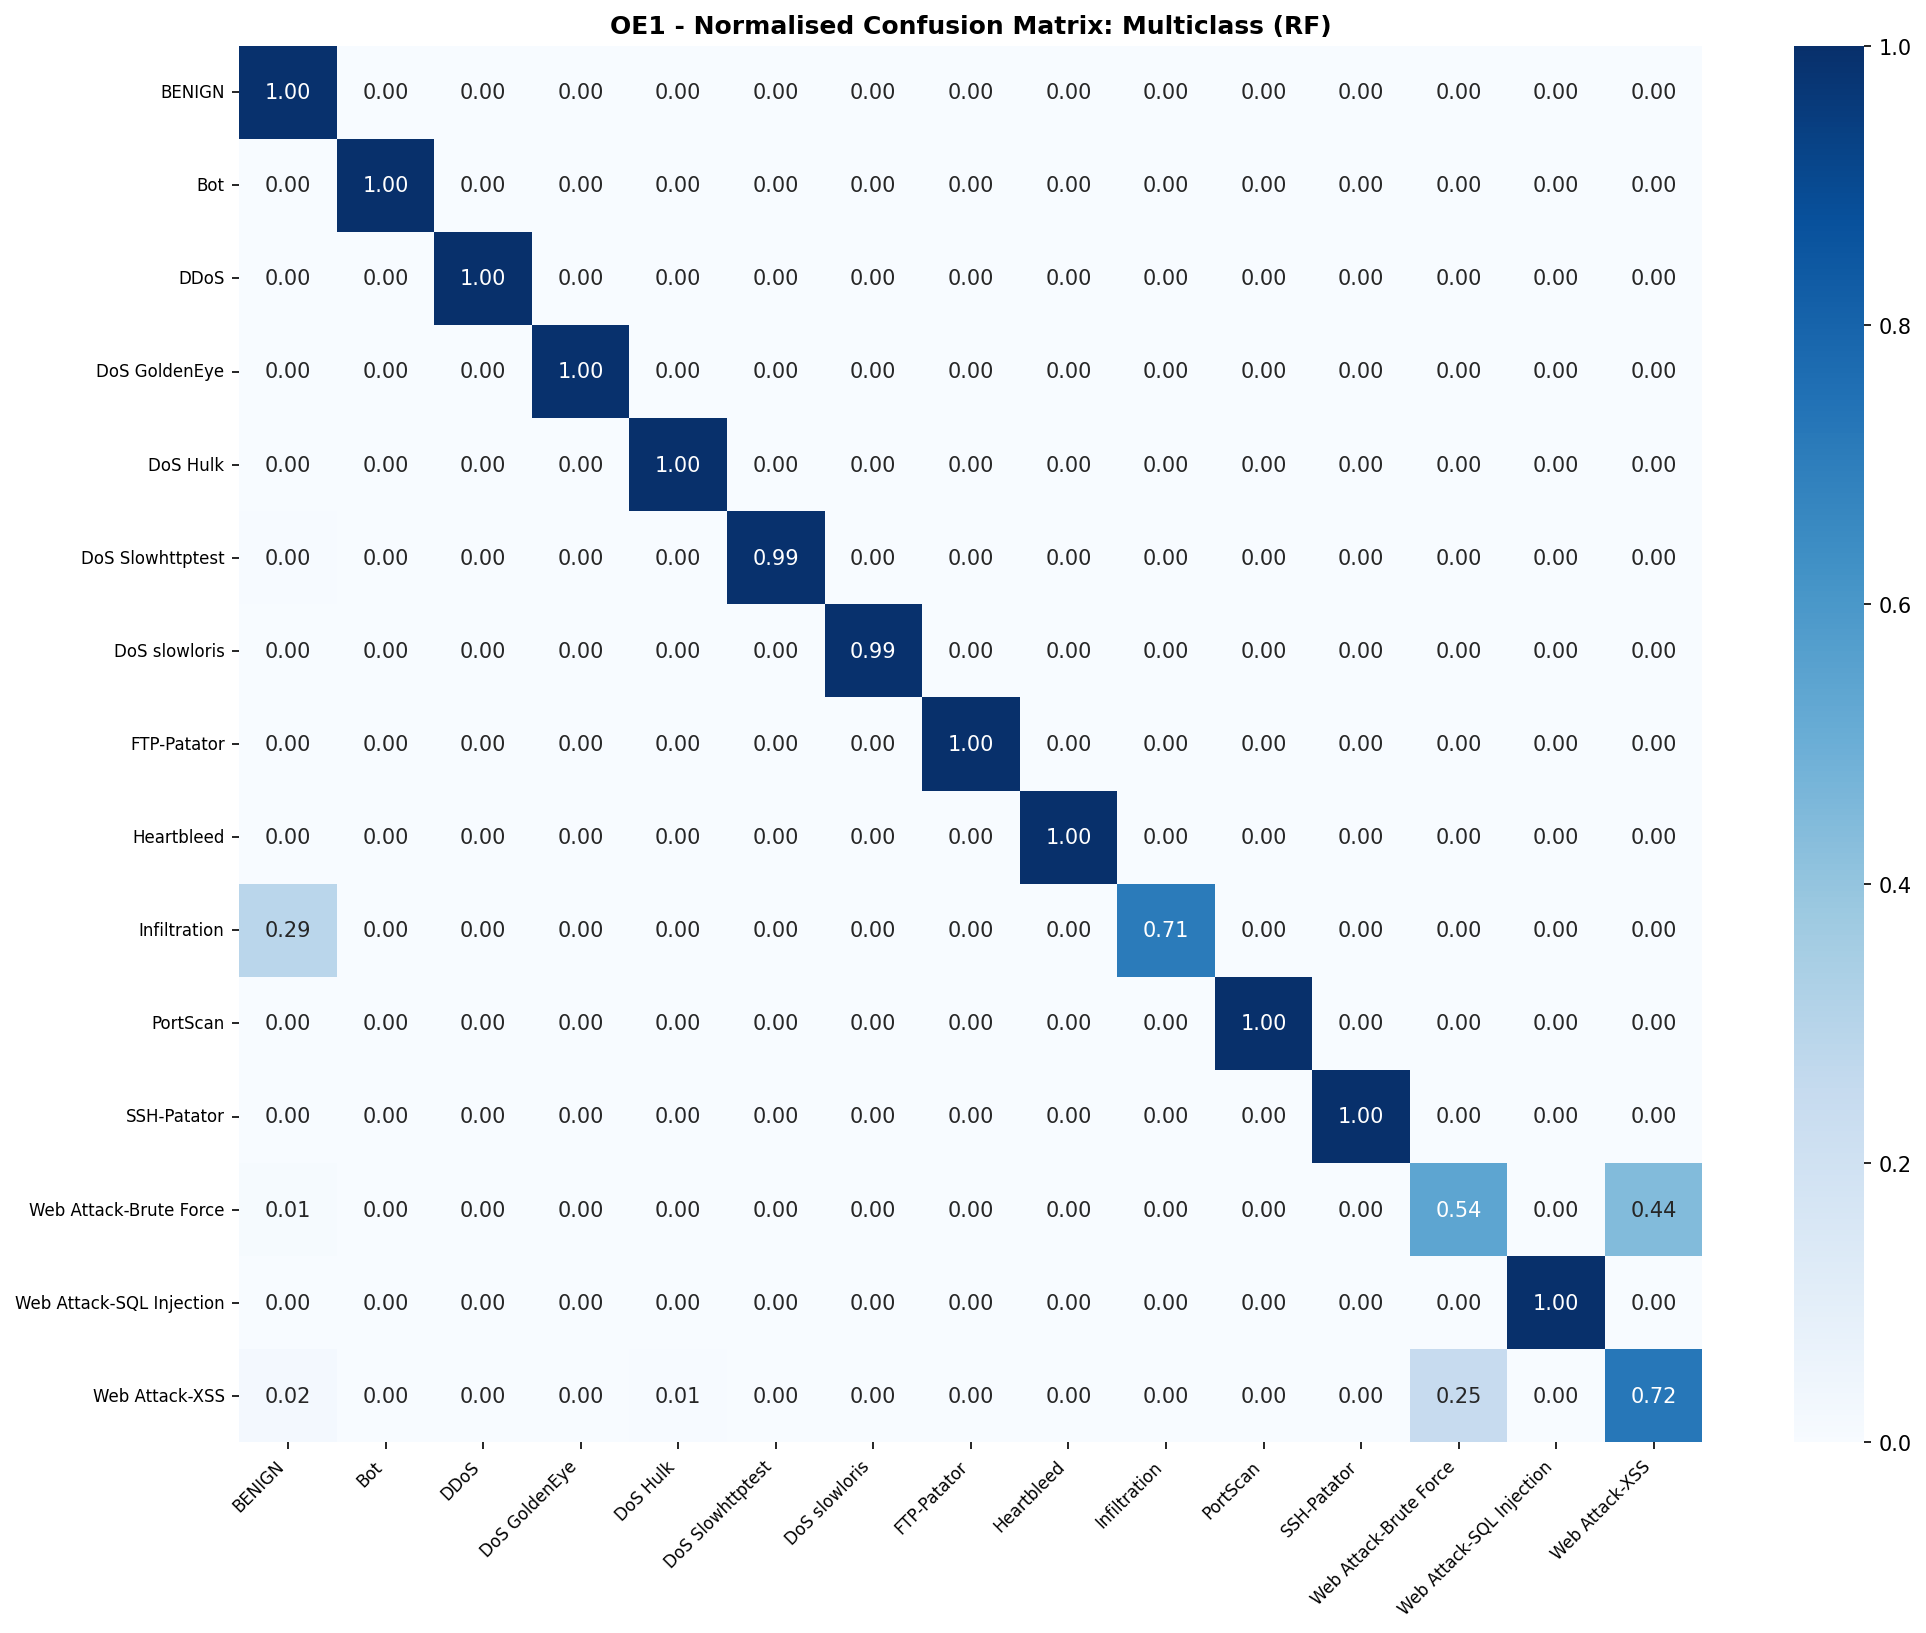

In [46]:
# ── OE1: Multiclass Classification (RF) ──────────────────────────────
print("=== MULTICLASS ATTACK TYPE CLASSIFICATION ===")
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

Xmc_tr, Xmc_te, ymc_tr, ymc_te = train_test_split(
    X_scaled, y_multi, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_multi)

rf_mc = RandomForestClassifier(n_estimators=100, max_depth=20,
                                random_state=RANDOM_STATE, n_jobs=-1,
                                class_weight="balanced")
rf_mc.fit(Xmc_tr, ymc_tr)
yp_mc = rf_mc.predict(Xmc_te)
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(ymc_te, yp_mc, target_names=class_names, zero_division=0))

cm_mc = confusion_matrix(ymc_te, yp_mc)
cm_pct = cm_mc.astype(float) / cm_mc.sum(axis=1)[:,np.newaxis]
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(cm_pct, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_title("OE1 - Normalised Confusion Matrix: Multiclass (RF)",
             fontweight="bold")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

=== 5-Fold CV (RF, 100K sample) ===
  accuracy    : 0.9979 +/- 0.0002
  f1          : 0.9938 +/- 0.0006
  precision   : 0.9967 +/- 0.0007
  recall      : 0.9910 +/- 0.0008
  roc_auc     : 0.9999 +/- 0.0000


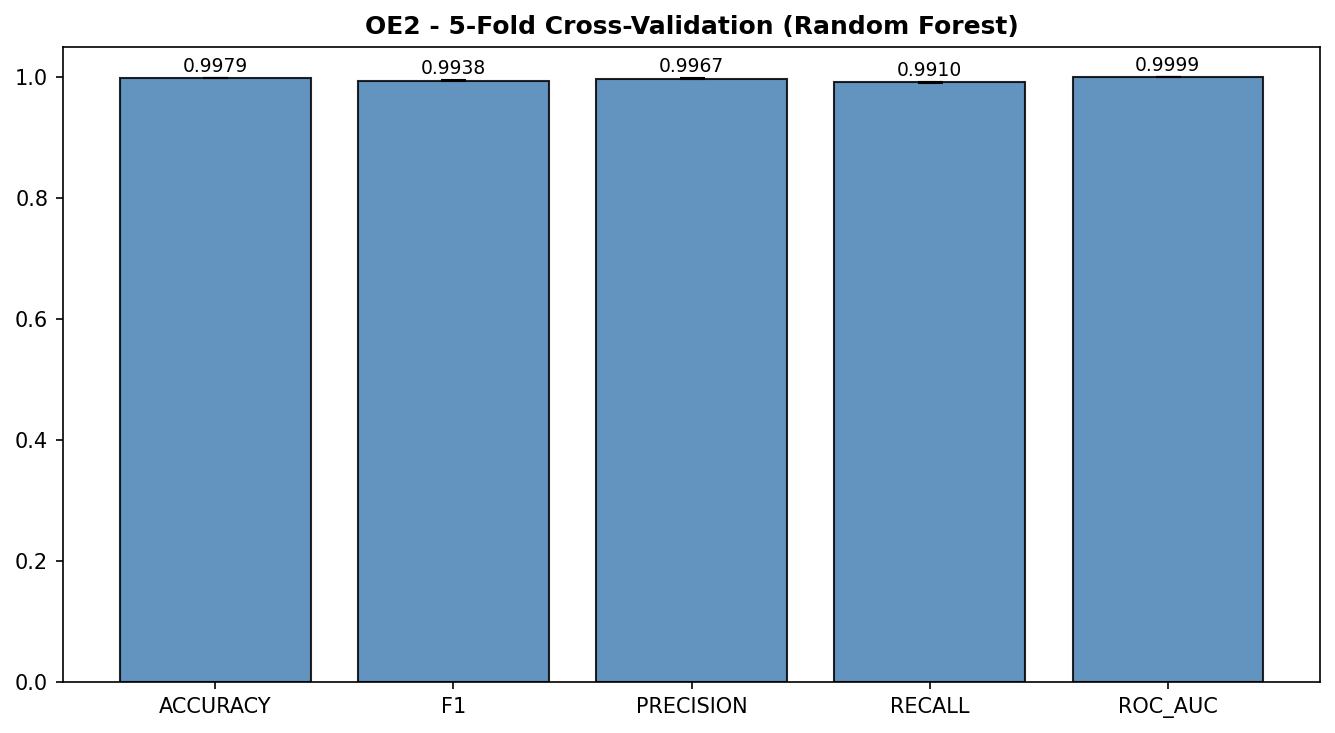

In [47]:
# ── OE2: 5-Fold Cross-Validation on Best Classifier ──────────────────
from sklearn.model_selection import StratifiedKFold, cross_validate

CV_N = 100_000
cv_idx = np.random.default_rng(RANDOM_STATE).choice(
         len(X_scaled), min(CV_N, len(X_scaled)), replace=False)
Xcv = X_scaled.iloc[cv_idx]
ycv = y_bin.iloc[cv_idx]

cv_model = RandomForestClassifier(n_estimators=50, max_depth=15,
                                   random_state=RANDOM_STATE, n_jobs=-1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_out = cross_validate(cv_model, Xcv, ycv, cv=skf,
                         scoring=["accuracy","f1","precision","recall","roc_auc"],
                         n_jobs=-1)

print("=== 5-Fold CV (RF, 100K sample) ===")
for m in ["accuracy","f1","precision","recall","roc_auc"]:
    v = cv_out[f"test_{m}"]
    print(f"  {m:12s}: {v.mean():.4f} +/- {v.std():.4f}")

metrics_cv = ["accuracy","f1","precision","recall","roc_auc"]
means = [cv_out[f"test_{m}"].mean() for m in metrics_cv]
stds  = [cv_out[f"test_{m}"].std()  for m in metrics_cv]

fig, ax = plt.subplots(figsize=(9,5))
x = np.arange(len(metrics_cv))
ax.bar(x, means, yerr=stds, capsize=6, color="steelblue", edgecolor="black", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels([m.upper() for m in metrics_cv])
ax.set_ylim(0, 1.05)
ax.set_title("OE2 - 5-Fold Cross-Validation (Random Forest)", fontweight="bold")
for xi,(m,s) in zip(x, zip(means,stds)):
    ax.text(xi, m+s+0.01, f"{m:.4f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

PCA variance: PC1=27.37%  PC2=15.26%  Total=42.63%


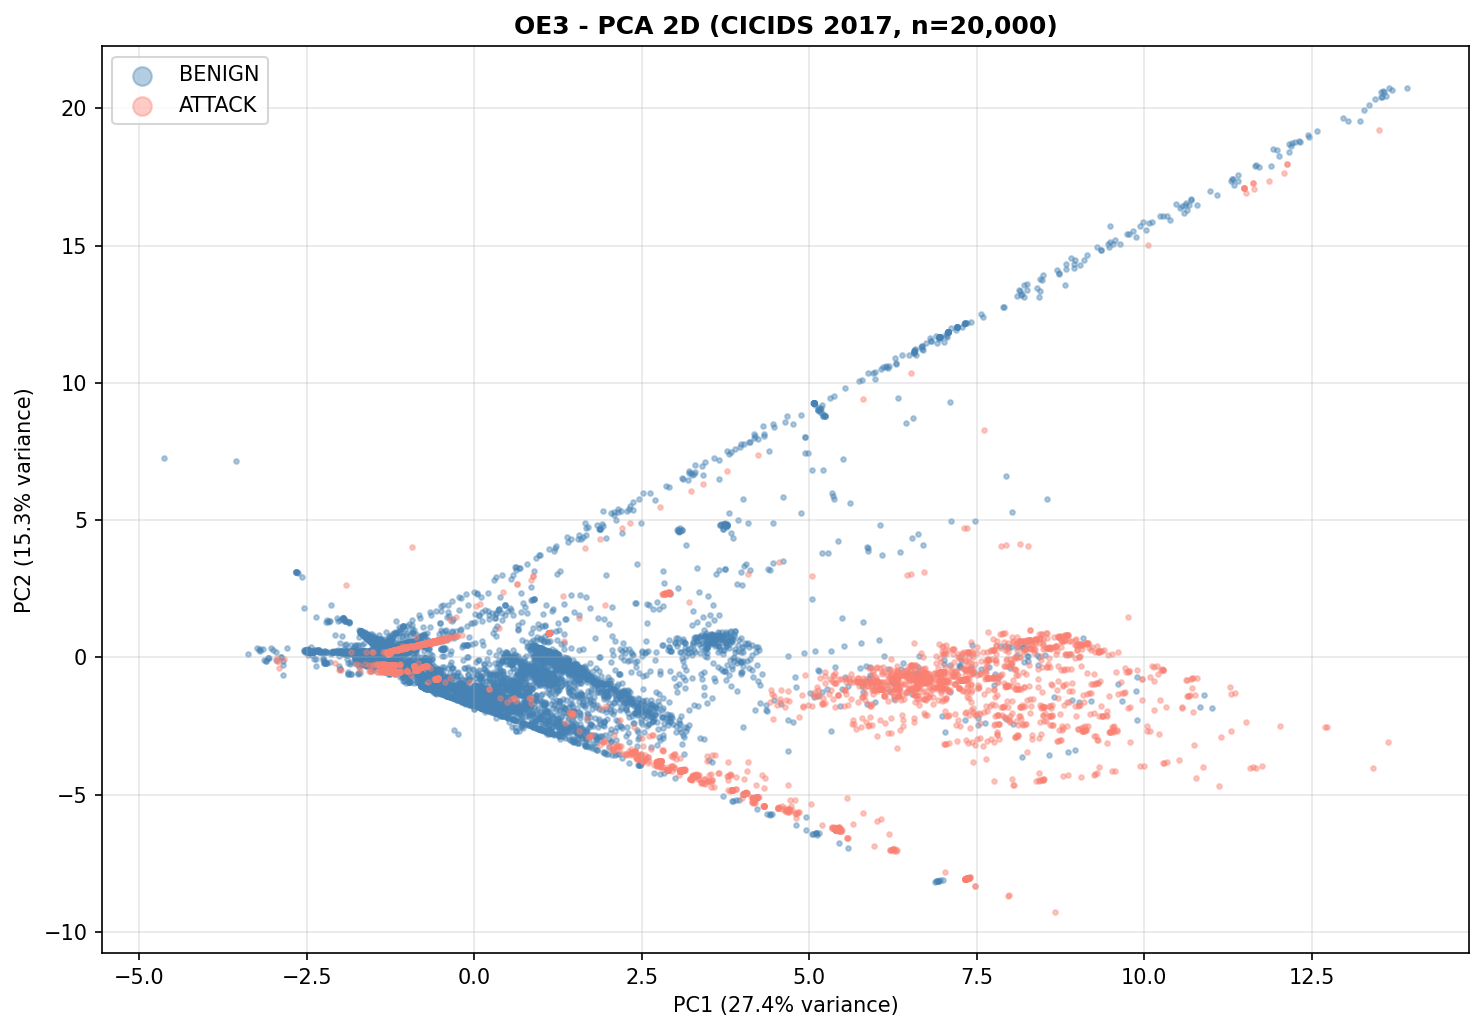

In [48]:
# ── OE3: PCA 2D Visualisation ─────────────────────────────────────────
from sklearn.decomposition import PCA

PCA_N = 20_000
pidx  = np.random.default_rng(RANDOM_STATE).choice(len(X_scaled), PCA_N, replace=False)
Xp    = X_scaled.iloc[pidx]
yp    = y_bin.iloc[pidx]

pca  = PCA(n_components=2, random_state=RANDOM_STATE)
Xpca = pca.fit_transform(Xp)
var  = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(10,7))
for cls, colour, label in [(0,"steelblue","BENIGN"),(1,"salmon","ATTACK")]:
    m = (yp==cls).values
    ax.scatter(Xpca[m,0], Xpca[m,1], c=colour, label=label, alpha=0.4, s=5)
ax.set_title(f"OE3 - PCA 2D (CICIDS 2017, n={PCA_N:,})", fontweight="bold")
ax.set_xlabel(f"PC1 ({var[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1%} variance)")
ax.legend(markerscale=4)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"PCA variance: PC1={var[0]:.2%}  PC2={var[1]:.2%}  Total={var.sum():.2%}")

## Final Summary

In [49]:
# ── Final Summary ─────────────────────────────────────────────────────
sep = "="*65
print(sep)
print("  ML REVIEW PROJECT - FINAL SUMMARY")
print(sep)
print(f"  Dataset  : CICIDS 2017 (Canadian Institute for Cybersecurity)")
print(f"  Samples  : {len(df):,} network flows")
print(f"  Features : {len(selected_features)} selected (from {len(cols_keep)} after corr pruning)")
print(f"  Classes  : {len(class_names)} attack categories")
print()
print("  PIPELINE:")
print("  [1] Data Collection & Understanding  - 8 CSV files loaded")
print("  [2] Data Cleaning                    - NaN/Inf/Duplicates/ZeroVar")
print("  [3] Feature Engineering              - Corr+RF selection, StandardScaler")
print("  [4] Class Imbalance                  - SMOTE (k=5)")
print()
print("  PART A - CLASSIFICATION (5 algorithms):")
for n, r in clf_results.items():
    f1 = r["metrics"]["F1-Score"]
    acc = r["metrics"]["Accuracy"]
    print(f"    {n:38s}  F1={f1:.4f}  Acc={acc:.4f}")
best_a = cdf_a["F1-Score"].idxmax()
print(f"  -> Best: {best_a}  (F1={cdf_a.loc[best_a,'F1-Score']:.4f})")
print()
print("  PART B - REGRESSION (10 algorithms):")
for n, r in reg_results.items():
    r2 = r["metrics"]["R2 Score"]
    rmse = r["metrics"]["RMSE"]
    print(f"    {n:42s}  R2={r2:.4f}  RMSE={rmse:.4f}")
best_b = rdf["R2 Score"].idxmax()
print(f"  -> Best: {best_b}  (R2={rdf.loc[best_b,'R2 Score']:.4f})")
print()
print("  OPTIONAL EXTENSIONS:")
print("  [OE1] Multiclass classification (14 attack types)")
print("  [OE2] 5-Fold Cross-Validation")
print("  [OE3] PCA 2D Visualisation")
print(sep)


  ML REVIEW PROJECT - FINAL SUMMARY
  Dataset  : CICIDS 2017 (Canadian Institute for Cybersecurity)
  Samples  : 2,522,362 network flows
  Features : 30 selected (from 46 after corr pruning)
  Classes  : 15 attack categories

  PIPELINE:
  [1] Data Collection & Understanding  - 8 CSV files loaded
  [2] Data Cleaning                    - NaN/Inf/Duplicates/ZeroVar
  [3] Feature Engineering              - Corr+RF selection, StandardScaler
  [4] Class Imbalance                  - SMOTE (k=5)

  PART A - CLASSIFICATION (5 algorithms):
    A1 - Logistic Regression                F1=0.8189  Acc=0.9278
    A2 - Decision Tree                      F1=0.9958  Acc=0.9986
    A3 - Random Forest                      F1=0.9967  Acc=0.9989
    A4 - XGBoost                            F1=0.9970  Acc=0.9990
    A5 - K-Nearest Neighbors                F1=0.9510  Acc=0.9828
  -> Best: A4 - XGBoost  (F1=0.9970)

  PART B - REGRESSION (10 algorithms):
    B1 - Linear Regression                      R2=0.709